# 05 - Estudo de hiperparâmetros, busca final e treino do modelo final

**Protocolo**
- Configuração de referência (baseline): 2 camadas ocultas × 32 neurônios, ReLU, Adam, η = 10⁻³, batch 32, até 200
  épocas com early stopping (paciência 20, restaura o melhor estado), sem weight decay, sem dropout, MSE
  (regressão) / BCE sem `pos_weight` (classificação), features padronizadas.
- **Um fator por vez:** cada variação altera só um hiperparâmetro em relação ao baseline.
- **5 sementes** (0 a 4) por configuração, as mesmas em todas as variações; resultados em média ± desvio.
- Mesmo máximo de épocas (200) em todas as variações, exceto no estudo do próprio número de épocas.
- **Todas as decisões usam a validação** (1.440 pacientes). O teste só é consultado no fim deste notebook, depois
  de a configuração final e o limiar estarem congelados.
- Métrica principal: RMSE (bpm) na regressão e F1 da classe positiva na classificação (limiar 0,5 durante o estudo).

Hiperparâmetros avaliados nos dois problemas: os 6 obrigatórios (neurônios, camadas, ativação, otimizador, taxa de
aprendizado, batch) e 5 opcionais (épocas/early stopping, weight decay, dropout, função de perda / `pos_weight`,
padronização das features). Depois: 2 varreduras 2D (mapas de calor), tabela de sensibilidade, busca aleatória
com 30 configurações e treino da configuração final.

Todas as execuções ficam registradas em `logs/hiperparametros.csv` (métricas) e `logs/curvas.jsonl` (perda por
época). Uma execução já registrada não é refeita; com o log vazio, o estudo completo leva cerca de 40 minutos em 6
processos paralelos.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

from src.config import MODELS, LOGS, ROOT, SEMENTES, TABLES, indices_split, ler_dataset, preparar, salvar_fig, salvar_tabela
from src.experiments import (GRADES_2D, carregar_log, chave_cfg, estudos, montar_cfg, resumir, rodar,
                             sensibilidade, tarefas_estudo, tarefas_grade)
from src.metrics import METRICA_PRINCIPAL, metricas_classificacao, metricas_regressao
from src.train import BASELINE, avaliar, executar, prever, salvar_checkpoint
from src.visualization import NOME_PROBLEMA, curvas_estudo, mapa_calor, metrica_por_valor
from src import inference

torch.set_num_threads(1)
pd.set_option("display.max_columns", 30)
PROBLEMAS = ("regressao", "classificacao")

## 1. Execução dos estudos de um fator por vez e das varreduras 2D

In [2]:
tarefas = []
for p in PROBLEMAS:
    for variacoes in estudos(p).values():
        tarefas += tarefas_estudo(p, variacoes)
    for g in GRADES_2D:
        tarefas += tarefas_estudo(p, tarefas_grade(g), SEMENTES[:3])
rodar(tarefas)
log = carregar_log()
print("Execuções registradas no log:", len(log))

741 tarefas, 741 já registradas, 0 a executar
Execuções registradas no log: 779


## 2. Resultados por hiperparâmetro

Para cada hiperparâmetro: tabela (valor, nº de parâmetros treináveis, métrica no treino e na validação em média ±
desvio entre sementes, gap treino − validação, época do melhor estado, épocas executadas e tempo de treino), gráfico
da métrica em função do valor e curvas de perda por época (média das sementes; faixa = ±1 desvio; linha tracejada =
época média do melhor estado).

Sinal do gap: no F1, gap > 0 = pior na validação; no RMSE, gap < 0 = erro maior na validação.

In [3]:
TITULOS = {
    "neuronios": "Neurônios por camada (2 camadas ocultas)", "camadas": "Número de camadas ocultas (32 neurônios)",
    "ativacao": "Função de ativação", "otimizador": "Otimizador (η = 10⁻³)", "lr": "Taxa de aprendizado η (Adam)",
    "batch": "Tamanho do batch", "epocas_es": "Número de épocas e early stopping", "weight_decay": "Weight decay (L2)",
    "dropout": "Dropout", "padronizar": "Padronização das features", "perda": "Função de perda (regressão)",
    "pos_weight": "pos_weight da BCE (classificação)",
}
TABELAS = {p: {} for p in PROBLEMAS}
for p in PROBLEMAS:
    for nome, variacoes in estudos(p).items():
        TABELAS[p][nome] = resumir(p, variacoes, log)
        salvar_tabela(TABELAS[p][nome], f"hp_{nome}_{p}")

def mostrar(nome):
    for p in PROBLEMAS:
        if nome not in TABELAS[p]:
            continue
        met = METRICA_PRINCIPAL[p]
        t = TABELAS[p][nome]
        fmt = (lambda m, s: f"{m:.3f} ± {s:.3f}") if met == "RMSE" else (lambda m, s: f"{m:.4f} ± {s:.4f}")
        tab = pd.DataFrame({
            "valor": t["valor"], "parâmetros": t["n_parametros"],
            f"{met} treino": [fmt(m, s) for m, s in zip(t[f"treino_{met}_media"], t[f"treino_{met}_desvio"])],
            f"{met} validação": [fmt(m, s) for m, s in zip(t[f"val_{met}_media"], t[f"val_{met}_desvio"])],
            "gap": t["gap_media"].round(4), "melhor época": t["melhor_epoca_media"].round(1),
            "épocas exec.": t["epocas_executadas_media"].round(1), "tempo (s)": t["tempo_treino_s_media"].round(2)})
        print(f"\n{NOME_PROBLEMA[p]} - {TITULOS[nome]}")
        display(tab)

def graficos(nome, ylim_reg=None, ylim_clf=None, log_y=False, max_epoca=None, ylim_metrica=None):
    tabs = {p: TABELAS[p][nome] for p in PROBLEMAS if nome in TABELAS[p]}
    metrica_por_valor(tabs, TITULOS[nome], log=log, ylim=ylim_metrica)
    salvar_fig(f"hp_{nome}")
    plt.show()
    for p, t in tabs.items():
        curvas_estudo(p, t, f"{NOME_PROBLEMA[p]} - {TITULOS[nome]}: curvas de perda",
                      ylim=ylim_reg if p == "regressao" else ylim_clf, log_y=log_y, max_epoca=max_epoca)
        salvar_fig(f"hp_{nome}_curvas_{p}")
        plt.show()

### 2.1 Neurônios por camada


Regressão - Neurônios por camada (2 camadas ocultas)


,valor,parâmetros,RMSE treino,RMSE validação,gap,melhor época,épocas exec.,tempo (s)
0,2,71,13.736 ± 4.240,13.538 ± 4.178,0.1977,58.0,78.0,9.33
1,4,149,11.777 ± 0.029,11.724 ± 0.041,0.0528,35.8,55.8,6.66
2,8,329,11.747 ± 0.064,11.808 ± 0.025,-0.0607,10.8,30.8,3.68
3,16,785,11.593 ± 0.113,11.874 ± 0.032,-0.2812,11.4,31.4,3.81
4,32,2081,11.639 ± 0.158,11.844 ± 0.078,-0.2057,4.4,24.4,3.02
5,64,6209,11.561 ± 0.135,11.893 ± 0.072,-0.3324,3.4,23.4,2.97
6,128,20609,11.514 ± 0.108,11.898 ± 0.063,-0.3846,2.6,22.6,3.15



Classificação - Neurônios por camada (2 camadas ocultas)


,valor,parâmetros,F1 treino,F1 validação,gap,melhor época,épocas exec.,tempo (s)
0,2,71,0.6748 ± 0.3772,0.6560 ± 0.3667,0.0188,80.6,100.6,13.34
1,4,149,0.8461 ± 0.0039,0.8188 ± 0.0036,0.0273,35.0,55.0,7.21
2,8,329,0.8457 ± 0.0024,0.8210 ± 0.0054,0.0247,10.0,30.0,4.00
3,16,785,0.8478 ± 0.0040,0.8204 ± 0.0045,0.0274,6.6,26.6,3.54
4,32,2081,0.8532 ± 0.0025,0.8233 ± 0.0039,0.0299,6.0,26.0,3.41
5,64,6209,0.8551 ± 0.0049,0.8192 ± 0.0054,0.0359,4.0,24.0,3.32
6,128,20609,0.8623 ± 0.0071,0.8205 ± 0.0027,0.0417,4.0,24.0,3.56


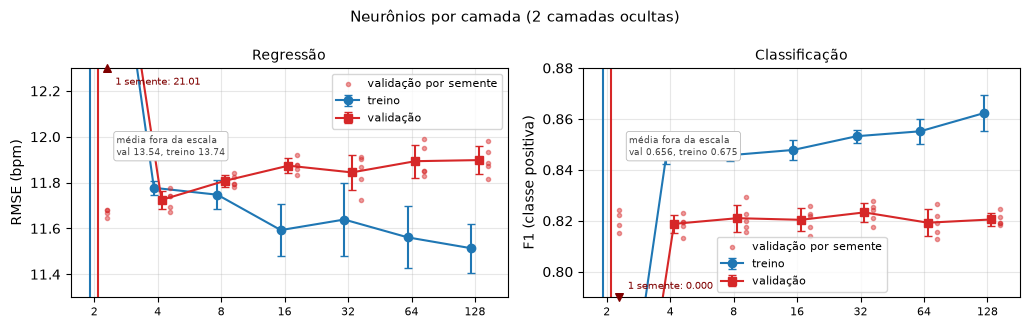

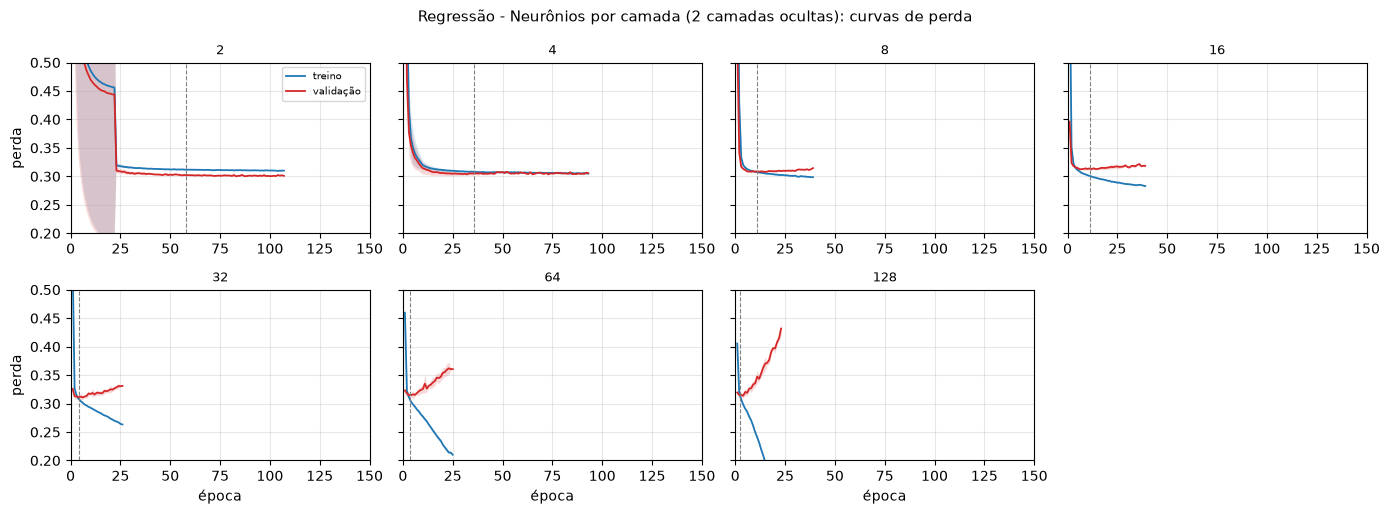

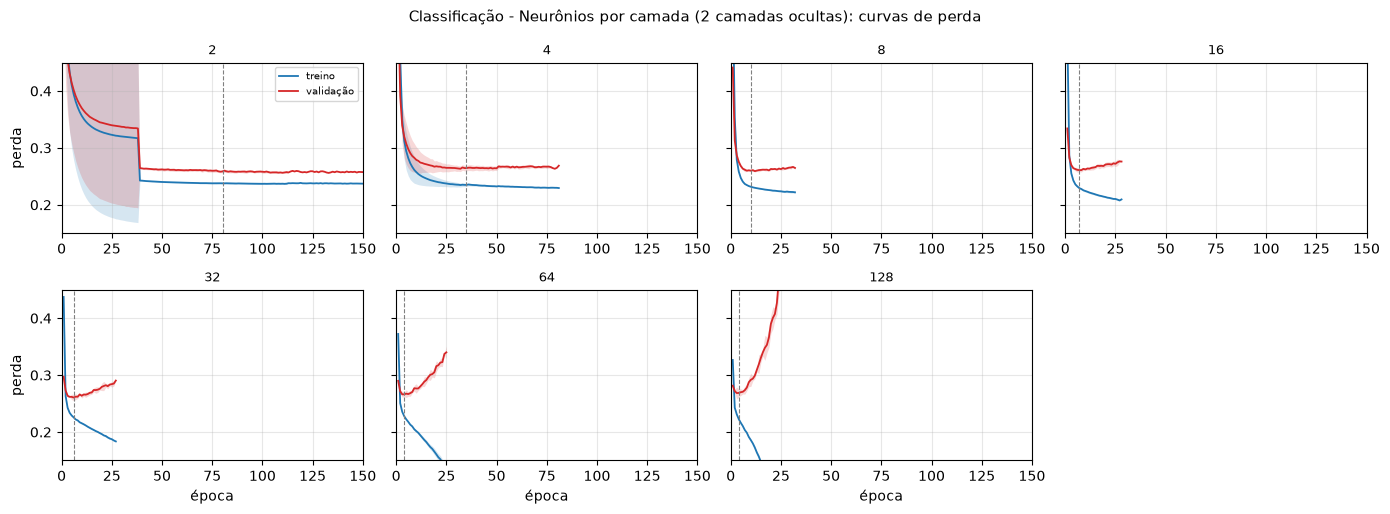

In [4]:
mostrar("neuronios")
graficos("neuronios", ylim_reg=(0.2, 0.5), ylim_clf=(0.15, 0.45), max_epoca=150,
         ylim_metrica={"regressao": (11.3, 12.3), "classificacao": (0.79, 0.88)})

Com 2 neurônios, uma das 5 sementes (semente 3) **colapsou** nos dois problemas: RMSE de treino = 21,3 bpm (igual ao
desvio do target, ou seja, a rede prevê uma constante) e F1 = 0 (nunca prevê doença). Com só 2 ReLUs por camada,
basta que ambas fiquem com entrada negativa para todos os pacientes para que a saída fique constante e o gradiente
seja zero (*dying ReLU*); a rede não se recupera. As outras 4 sementes treinam normalmente, mas devagar (melhor
época entre 46 e 153) e, na regressão, chegam a um RMSE de validação de ~11,67 bpm, melhor que o do baseline. A partir de 4 neurônios, a validação fica praticamente estável, enquanto o treino continua melhorando
com a capacidade: o gap cresce e o early stopping para cada vez mais cedo.

In [5]:
semente_colapso = log[(log["chave"] == chave_cfg(montar_cfg({"neuronios": 2})))][
    ["problema", "seed", "treino_RMSE", "val_RMSE", "treino_F1", "val_F1", "melhor_epoca"]].sort_values(["problema", "seed"])
semente_colapso.round(4)

,problema,seed,treino_RMSE,val_RMSE,treino_F1,val_F1,melhor_epoca
273,classificacao,0,NaN,NaN,0.8435,0.8182,57
282,classificacao,1,NaN,NaN,0.8425,0.8244,153
275,classificacao,2,NaN,NaN,0.8457,0.8221,83
271,classificacao,3,NaN,NaN,0.0000,0.0000,18
278,classificacao,4,NaN,NaN,0.8423,0.8153,92
4,regressao,0,11.8307,11.6669,NaN,NaN,72
2,regressao,1,11.8632,11.6824,NaN,NaN,46
6,regressao,2,11.8211,11.6816,NaN,NaN,87
0,regressao,3,21.3199,21.0119,NaN,NaN,2
5,regressao,4,11.8440,11.6476,NaN,NaN,83


### 2.2 Número de camadas ocultas


Regressão - Número de camadas ocultas (32 neurônios)


,valor,parâmetros,RMSE treino,RMSE validação,gap,melhor época,épocas exec.,tempo (s)
0,1,1025,11.676 ± 0.092,11.758 ± 0.049,-0.0827,5.6,25.6,2.49
1,2,2081,11.639 ± 0.158,11.844 ± 0.078,-0.2057,4.4,24.4,3.02
2,3,3137,11.690 ± 0.122,11.878 ± 0.098,-0.1881,3.6,23.6,3.51
3,5,5249,11.620 ± 0.183,11.890 ± 0.105,-0.2696,5.0,25.0,4.91



Classificação - Número de camadas ocultas (32 neurônios)


,valor,parâmetros,F1 treino,F1 validação,gap,melhor época,épocas exec.,tempo (s)
0,1,1025,0.8510 ± 0.0023,0.8215 ± 0.0062,0.0295,8.8,28.8,3.09
1,2,2081,0.8532 ± 0.0025,0.8233 ± 0.0039,0.0299,6.0,26.0,3.41
2,3,3137,0.8539 ± 0.0048,0.8171 ± 0.0042,0.0368,5.2,25.2,3.97
3,5,5249,0.8562 ± 0.0059,0.8171 ± 0.0031,0.0391,5.2,25.2,5.30


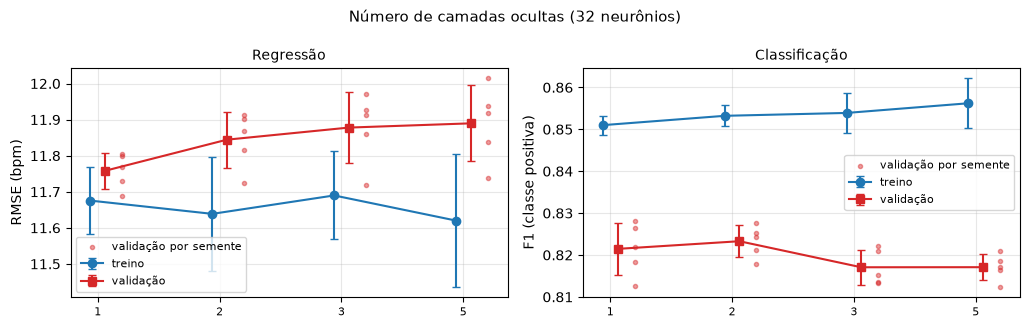

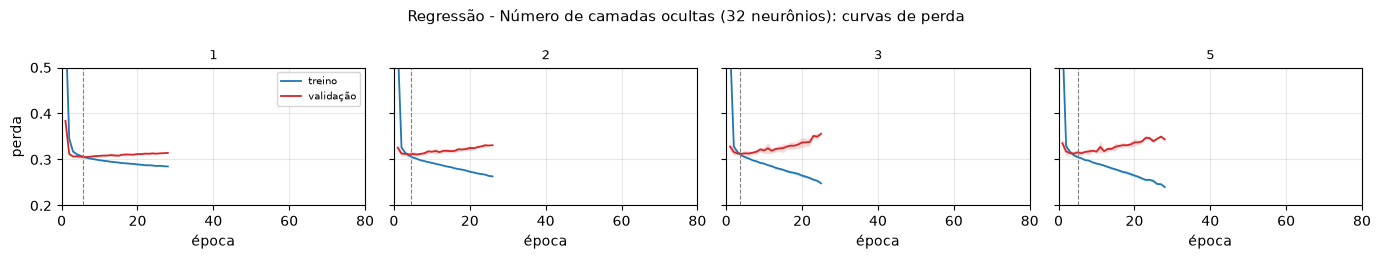

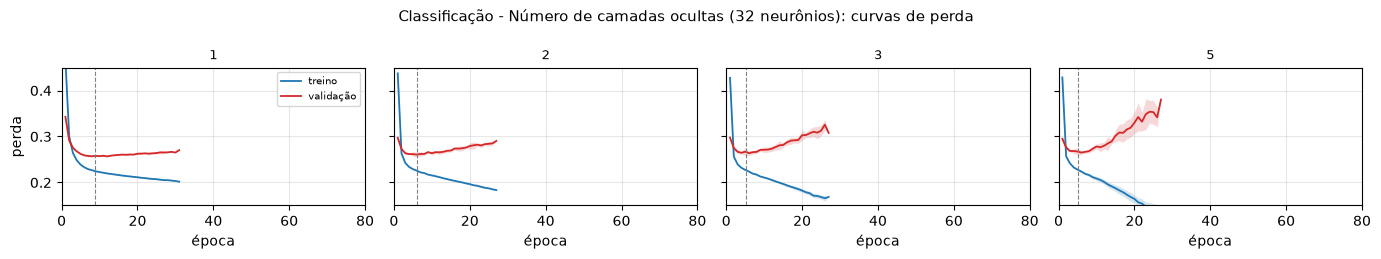

In [6]:
mostrar("camadas")
graficos("camadas", ylim_reg=(0.2, 0.5), ylim_clf=(0.15, 0.45), max_epoca=80)

### 2.3 Função de ativação


Regressão - Função de ativação


,valor,parâmetros,RMSE treino,RMSE validação,gap,melhor época,épocas exec.,tempo (s)
0,ReLU,2081,11.639 ± 0.158,11.844 ± 0.078,-0.2057,4.4,24.4,3.02
1,LeakyReLU,2081,11.614 ± 0.104,11.843 ± 0.077,-0.2295,4.6,24.6,3.01
2,Tanh,2081,11.827 ± 0.018,11.779 ± 0.034,0.0478,7.0,27.0,3.41
3,Sigmoid,2081,11.783 ± 0.045,11.701 ± 0.017,0.0821,32.6,52.6,6.56
4,ELU,2081,11.845 ± 0.045,11.713 ± 0.022,0.1321,5.2,25.2,3.20
5,GELU,2081,11.734 ± 0.047,11.760 ± 0.054,-0.0251,4.6,24.6,3.67



Classificação - Função de ativação


,valor,parâmetros,F1 treino,F1 validação,gap,melhor época,épocas exec.,tempo (s)
0,ReLU,2081,0.8532 ± 0.0025,0.8233 ± 0.0039,0.0299,6.0,26.0,3.41
1,LeakyReLU,2081,0.8531 ± 0.0028,0.8222 ± 0.0033,0.0308,6.0,26.0,3.43
2,Tanh,2081,0.8409 ± 0.0036,0.8245 ± 0.0049,0.0164,6.2,26.2,3.54
3,Sigmoid,2081,0.8471 ± 0.0016,0.8251 ± 0.0034,0.0220,38.0,58.0,7.76
4,ELU,2081,0.8432 ± 0.0028,0.8227 ± 0.0058,0.0204,9.8,29.8,4.05
5,GELU,2081,0.8467 ± 0.0035,0.8221 ± 0.0055,0.0246,5.4,25.4,4.03


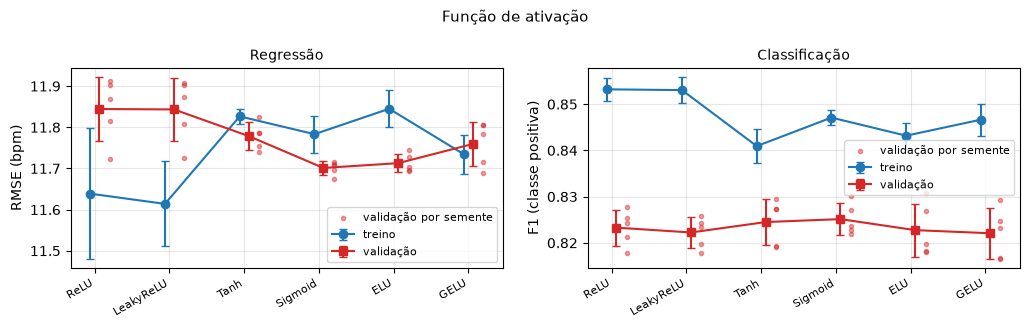

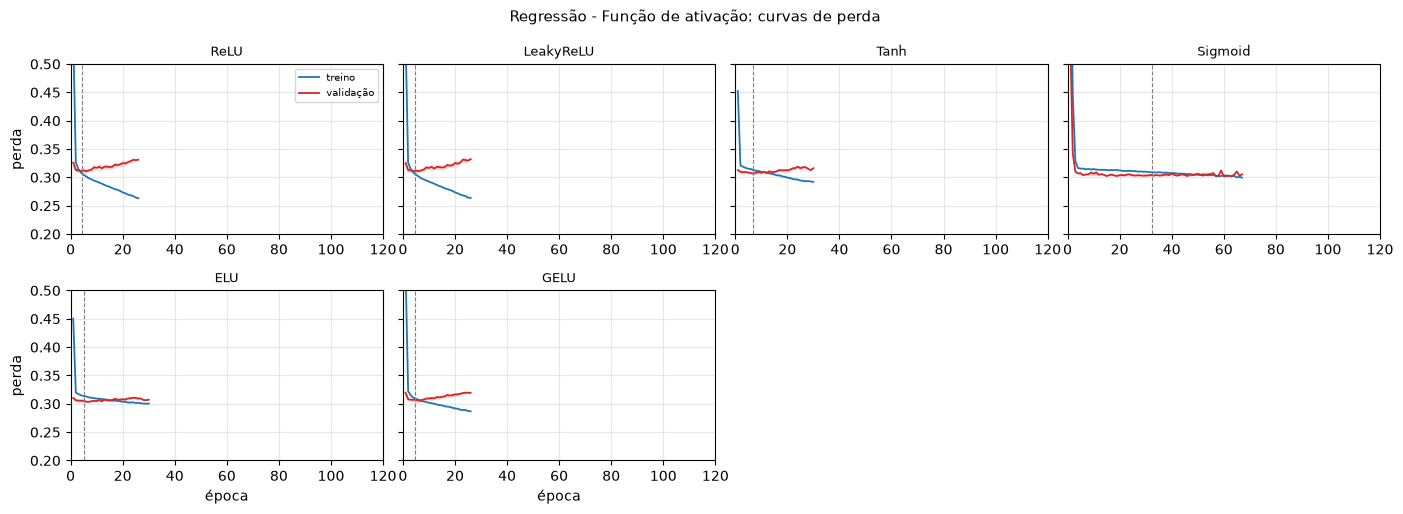

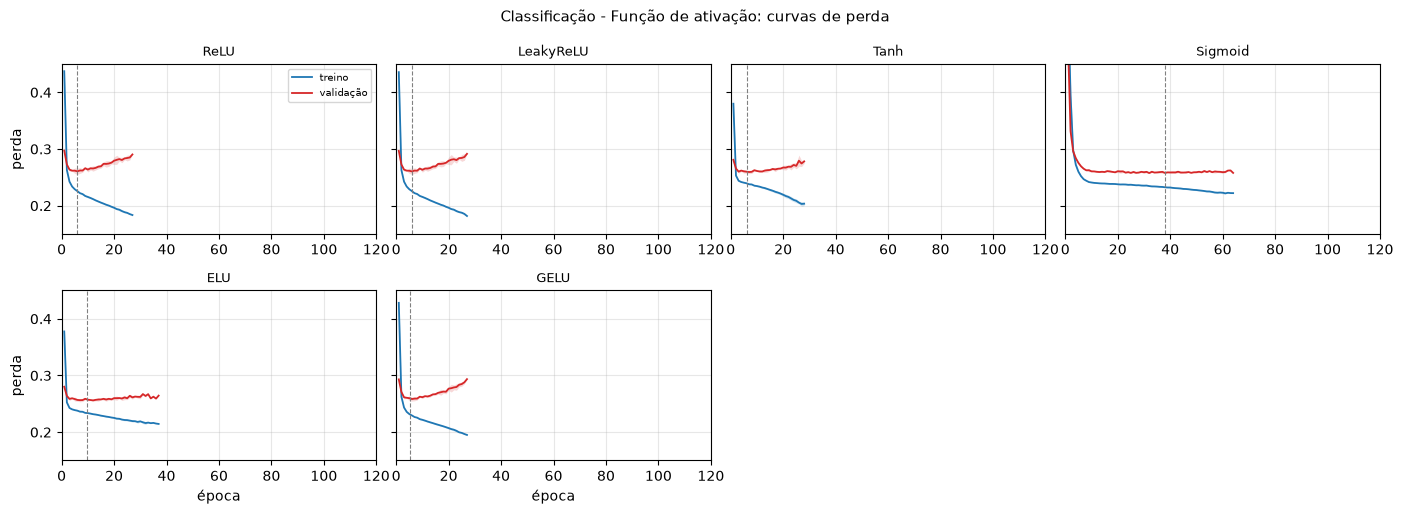

In [7]:
mostrar("ativacao")
graficos("ativacao", ylim_reg=(0.2, 0.5), ylim_clf=(0.15, 0.45), max_epoca=120)

A sigmoide é a única ativação que muda claramente a dinâmica: a melhor época passa de ~5 (ReLU) para ~33-38. A
derivada da sigmoide é no máximo 0,25, então o gradiente que chega à primeira camada é atenuado a cada camada e a
rede aprende mais devagar. Aqui isso não prejudicou o resultado final, porque com 2 camadas e early stopping há
épocas suficientes para convergir.

### 2.4 Otimizador


Regressão - Otimizador (η = 10⁻³)


,valor,parâmetros,RMSE treino,RMSE validação,gap,melhor época,épocas exec.,tempo (s)
0,SGD,2081,11.661 ± 0.038,11.837 ± 0.068,-0.1766,140.4,158.4,12.69
1,SGD_momentum,2081,11.651 ± 0.021,11.825 ± 0.059,-0.1742,15.2,35.2,3.21
2,RMSprop,2081,11.629 ± 0.149,11.846 ± 0.076,-0.2164,3.8,23.8,2.60
3,Adam,2081,11.639 ± 0.158,11.844 ± 0.078,-0.2057,4.4,24.4,3.02
4,AdamW,2081,11.641 ± 0.155,11.844 ± 0.075,-0.2027,4.4,24.4,3.13



Classificação - Otimizador (η = 10⁻³)


,valor,parâmetros,F1 treino,F1 validação,gap,melhor época,épocas exec.,tempo (s)
0,SGD,2081,0.8422 ± 0.0021,0.8132 ± 0.0034,0.0290,200.0,200.0,17.62
1,SGD_momentum,2081,0.8508 ± 0.0039,0.8216 ± 0.0046,0.0292,37.0,57.0,5.61
2,RMSprop,2081,0.8518 ± 0.0035,0.8201 ± 0.0032,0.0317,5.8,25.8,3.04
3,Adam,2081,0.8532 ± 0.0025,0.8233 ± 0.0039,0.0299,6.0,26.0,3.41
4,AdamW,2081,0.8531 ± 0.0021,0.8234 ± 0.0025,0.0298,6.0,26.0,3.63


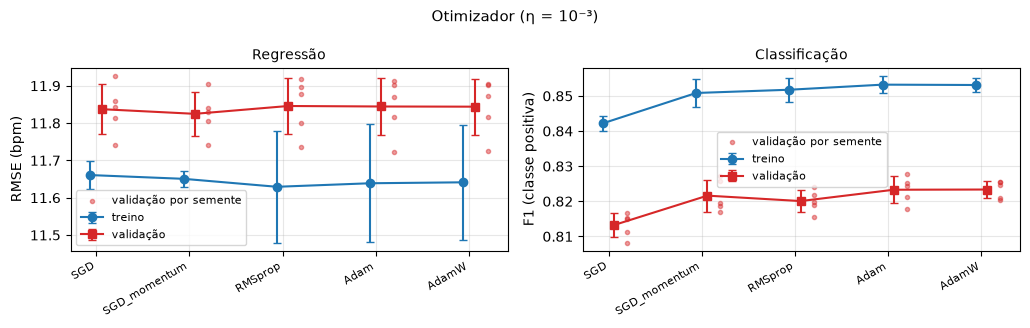

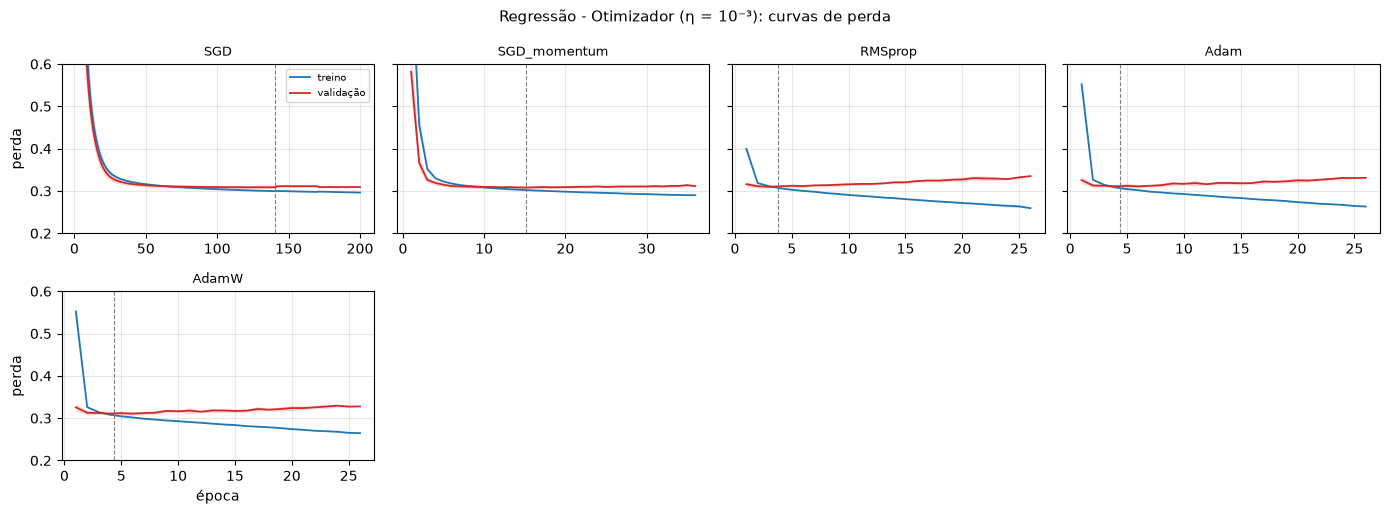

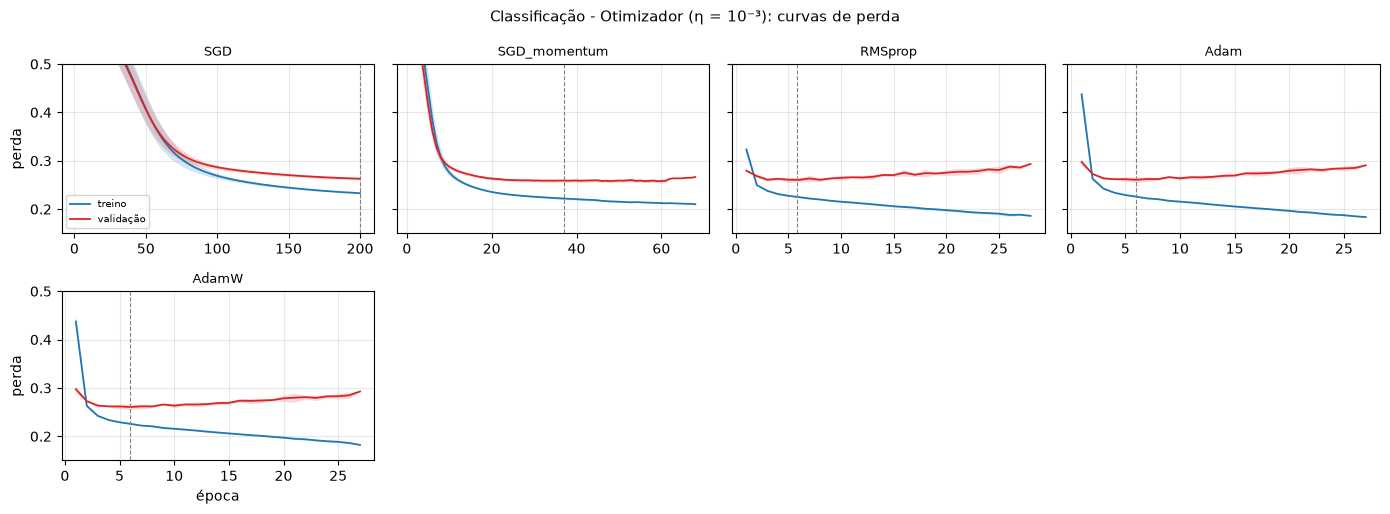

In [8]:
mostrar("otimizador")
graficos("otimizador", ylim_reg=(0.2, 0.6), ylim_clf=(0.15, 0.5))

### 2.5 Taxa de aprendizado


Regressão - Taxa de aprendizado η (Adam)


,valor,parâmetros,RMSE treino,RMSE validação,gap,melhor época,épocas exec.,tempo (s)
0,0.0001,2081,11.595 ± 0.077,11.843 ± 0.089,-0.2478,38.4,58.4,7.39
1,0.001,2081,11.639 ± 0.158,11.844 ± 0.078,-0.2057,4.4,24.4,3.02
2,0.01,2081,11.707 ± 0.164,11.933 ± 0.030,-0.2264,4.2,24.2,3.05
3,0.1,2081,12.496 ± 0.249,12.443 ± 0.235,0.0528,12.0,32.0,4.01
4,1.0,2081,21.344 ± 0.066,33.861 ± 26.324,-12.5171,36.2,56.2,7.11



Classificação - Taxa de aprendizado η (Adam)


,valor,parâmetros,F1 treino,F1 validação,gap,melhor época,épocas exec.,tempo (s)
0,0.0001,2081,0.8522 ± 0.0020,0.8208 ± 0.0022,0.0314,48.8,68.8,9.19
1,0.001,2081,0.8532 ± 0.0025,0.8233 ± 0.0039,0.0299,6.0,26.0,3.41
2,0.01,2081,0.8450 ± 0.0096,0.8089 ± 0.0089,0.0361,2.4,22.4,3.00
3,0.1,2081,0.8402 ± 0.0106,0.8010 ± 0.0101,0.0392,10.8,30.8,4.16
4,1.0,2081,0.0007 ± 0.0010,0.0018 ± 0.0041,-0.0011,18.6,38.6,5.32


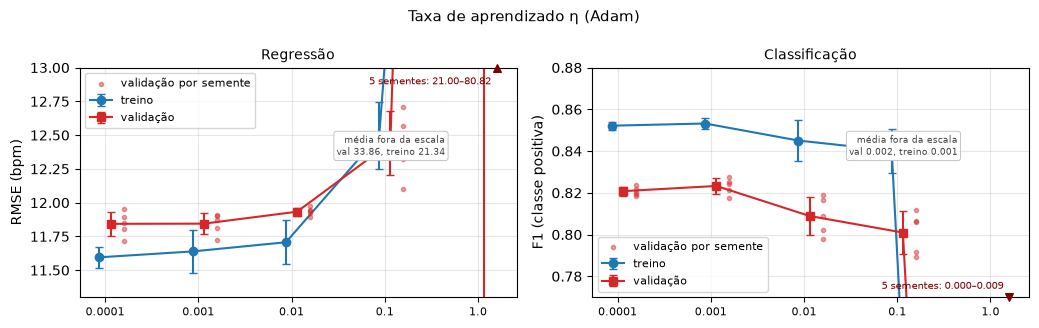

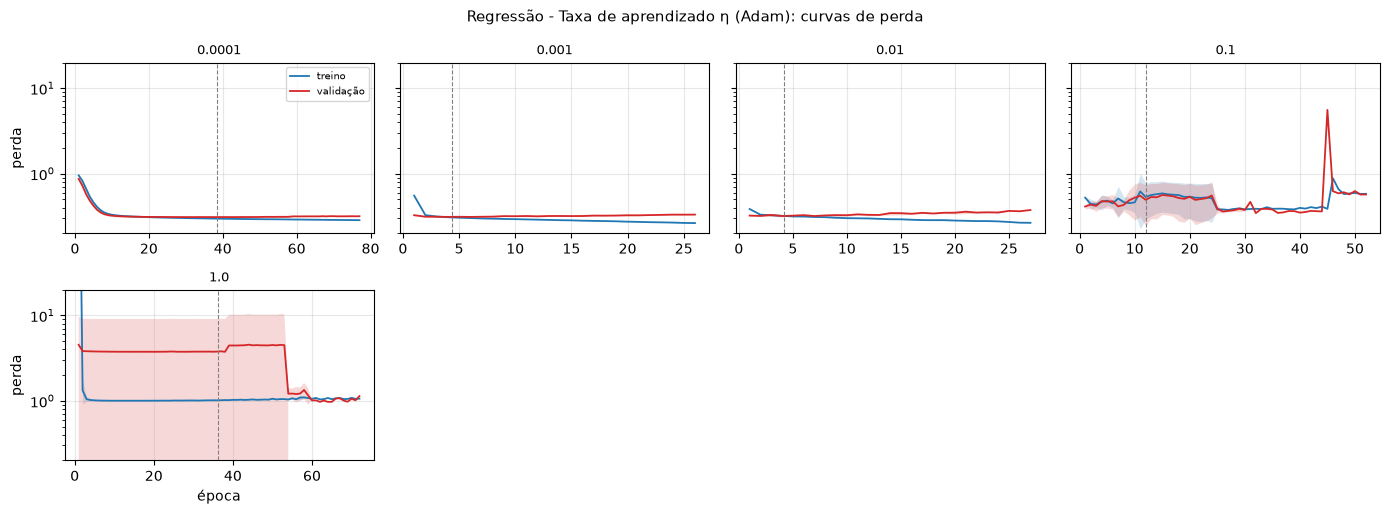

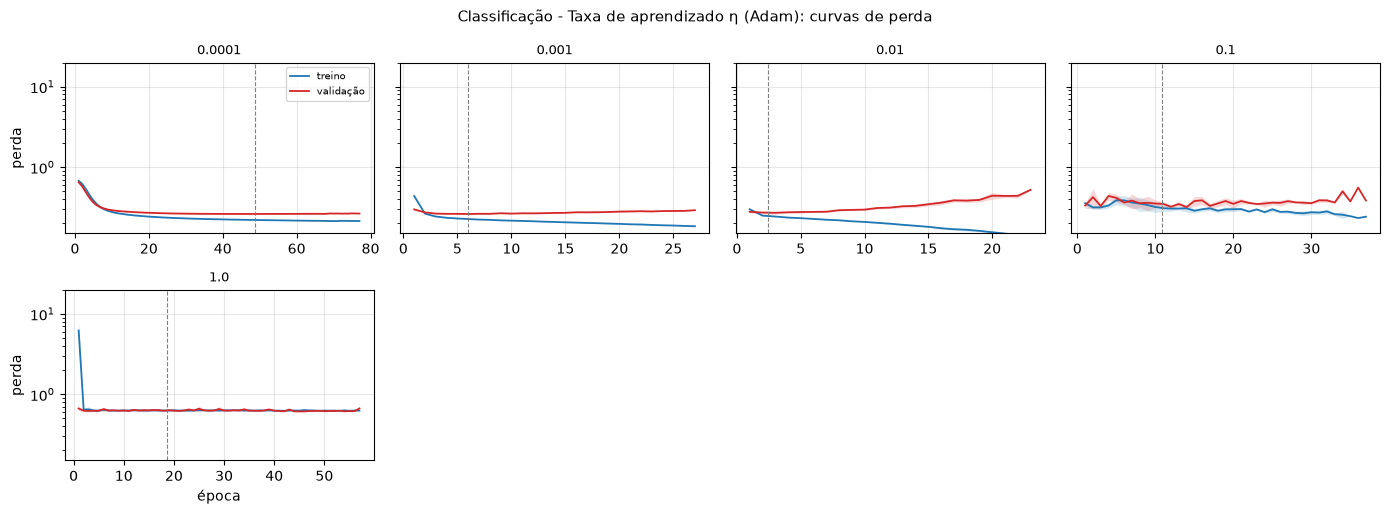

In [9]:
mostrar("lr")
graficos("lr", ylim_reg=(0.2, 20), ylim_clf=(0.15, 20), log_y=True,
         ylim_metrica={"regressao": (11.3, 13.0), "classificacao": (0.77, 0.88)})

Com η = 1, as 5 sementes acabam com saída constante: RMSE de treino de 21,3 bpm e F1 ≈ 0. Os passos enormes jogam os
pesos para uma região em que todas as ReLUs ficam inativas (*dying ReLU*) logo nas primeiras atualizações. Não há
NaN (a perda não explode), mas o gradiente zera e a rede para de aprender.

In [10]:
log[(log["chave"] == chave_cfg(montar_cfg({"lr": 1.0})))][
    ["problema", "seed", "treino_RMSE", "val_RMSE", "treino_F1", "val_F1", "melhor_epoca"]].sort_values(["problema", "seed"]).round(3)

,problema,seed,treino_RMSE,val_RMSE,treino_F1,val_F1,melhor_epoca
382,classificacao,0,NaN,NaN,0.000,0.000,21
383,classificacao,1,NaN,NaN,0.000,0.000,14
384,classificacao,2,NaN,NaN,0.002,0.000,18
381,classificacao,3,NaN,NaN,0.000,0.000,3
385,classificacao,4,NaN,NaN,0.001,0.009,37
110,regressao,0,21.332,25.459,NaN,NaN,39
114,regressao,1,21.299,21.002,NaN,NaN,52
112,regressao,2,21.460,80.824,NaN,NaN,33
113,regressao,3,21.316,21.011,NaN,NaN,39
111,regressao,4,21.315,21.010,NaN,NaN,18


### 2.6 Tamanho do batch


Regressão - Tamanho do batch


,valor,parâmetros,RMSE treino,RMSE validação,gap,melhor época,épocas exec.,tempo (s)
0,8,2081,11.634 ± 0.165,11.859 ± 0.074,-0.2249,3.2,23.2,11.47
1,32,2081,11.639 ± 0.158,11.844 ± 0.078,-0.2057,4.4,24.4,3.02
2,128,2081,11.584 ± 0.084,11.860 ± 0.083,-0.2754,9.4,29.4,1.06
3,512,2081,11.552 ± 0.067,11.882 ± 0.086,-0.3297,23.8,43.8,0.50
4,total,2081,11.598 ± 0.140,11.923 ± 0.094,-0.3251,147.6,163.6,0.75



Classificação - Tamanho do batch


,valor,parâmetros,F1 treino,F1 validação,gap,melhor época,épocas exec.,tempo (s)
0,8,2081,0.8526 ± 0.0028,0.8220 ± 0.0069,0.0305,4.0,24.0,12.68
1,32,2081,0.8532 ± 0.0025,0.8233 ± 0.0039,0.0299,6.0,26.0,3.41
2,128,2081,0.8533 ± 0.0023,0.8208 ± 0.0055,0.0325,12.0,32.0,1.10
3,512,2081,0.8511 ± 0.0041,0.8154 ± 0.0055,0.0357,28.2,48.2,0.63
4,total,2081,0.8511 ± 0.0024,0.8119 ± 0.0053,0.0392,200.0,200.0,0.97


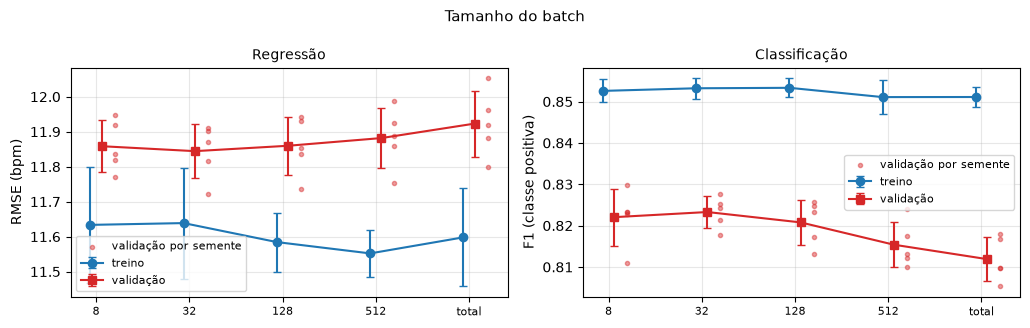

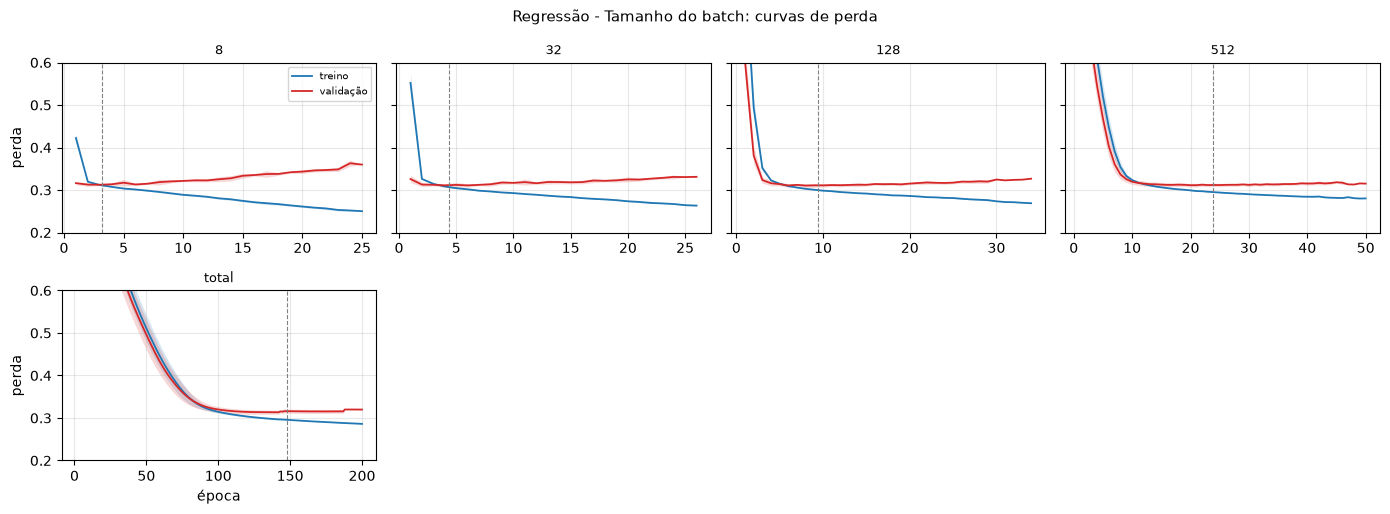

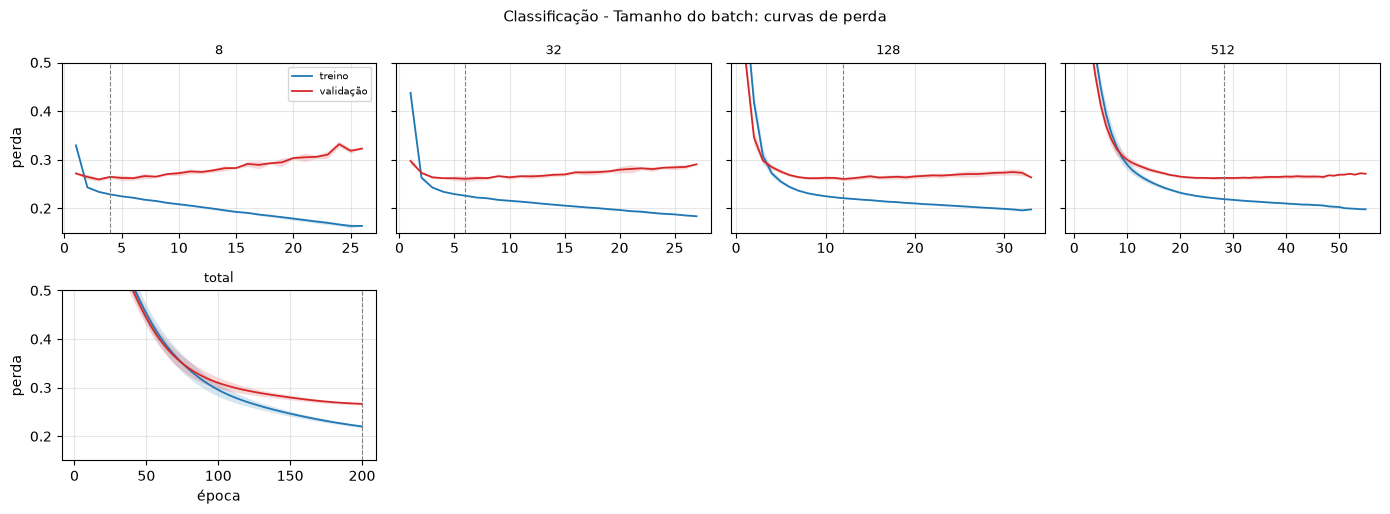

In [11]:
mostrar("batch")
graficos("batch", ylim_reg=(0.2, 0.6), ylim_clf=(0.15, 0.5))

Com 5.760 amostras de treino: batch 8 = 720 atualizações por época, 32 = 180, 128 = 45, 512 = 12, batch total = 1.

### 2.7 Número de épocas e early stopping (opcional)

Sem early stopping o modelo devolvido é o da **última** época; com early stopping, é o de menor perda de validação.


Regressão - Número de épocas e early stopping


,valor,parâmetros,RMSE treino,RMSE validação,gap,melhor época,épocas exec.,tempo (s)
0,"20 ép., sem ES",2081,10.972 ± 0.037,12.150 ± 0.123,-1.1783,4.4,20.0,2.72
1,"50 ép., sem ES",2081,10.042 ± 0.052,12.836 ± 0.124,-2.7947,4.4,50.0,6.18
2,"200 ép., sem ES",2081,8.509 ± 0.069,14.418 ± 0.229,-5.9086,4.4,200.0,24.83
3,"500 ép., sem ES",2081,7.787 ± 0.143,15.235 ± 0.285,-7.4472,4.4,500.0,63.03
4,"200 ép., pac. 5",2081,11.639 ± 0.158,11.844 ± 0.078,-0.2057,4.4,9.4,1.19
5,"200 ép., pac. 20",2081,11.639 ± 0.158,11.844 ± 0.078,-0.2057,4.4,24.4,3.02



Classificação - Número de épocas e early stopping


,valor,parâmetros,F1 treino,F1 validação,gap,melhor época,épocas exec.,tempo (s)
0,"20 ép., sem ES",2081,0.8737 ± 0.0012,0.8090 ± 0.0072,0.0647,6.0,20.0,2.63
1,"50 ép., sem ES",2081,0.9217 ± 0.0056,0.7917 ± 0.0117,0.1300,6.0,50.0,6.77
2,"200 ép., sem ES",2081,0.9941 ± 0.0059,0.7606 ± 0.0086,0.2335,6.0,200.0,27.16
3,"500 ép., sem ES",2081,1.0000 ± 0.0000,0.7569 ± 0.0107,0.2431,6.0,500.0,62.24
4,"200 ép., pac. 5",2081,0.8532 ± 0.0025,0.8233 ± 0.0039,0.0299,6.0,11.0,1.47
5,"200 ép., pac. 20",2081,0.8532 ± 0.0025,0.8233 ± 0.0039,0.0299,6.0,26.0,3.41


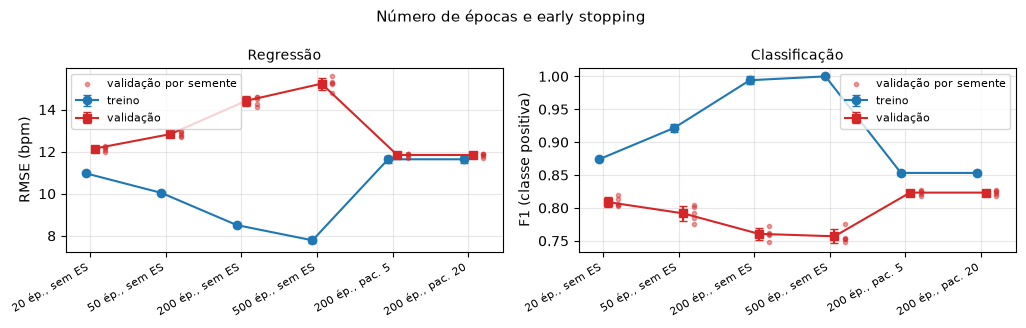

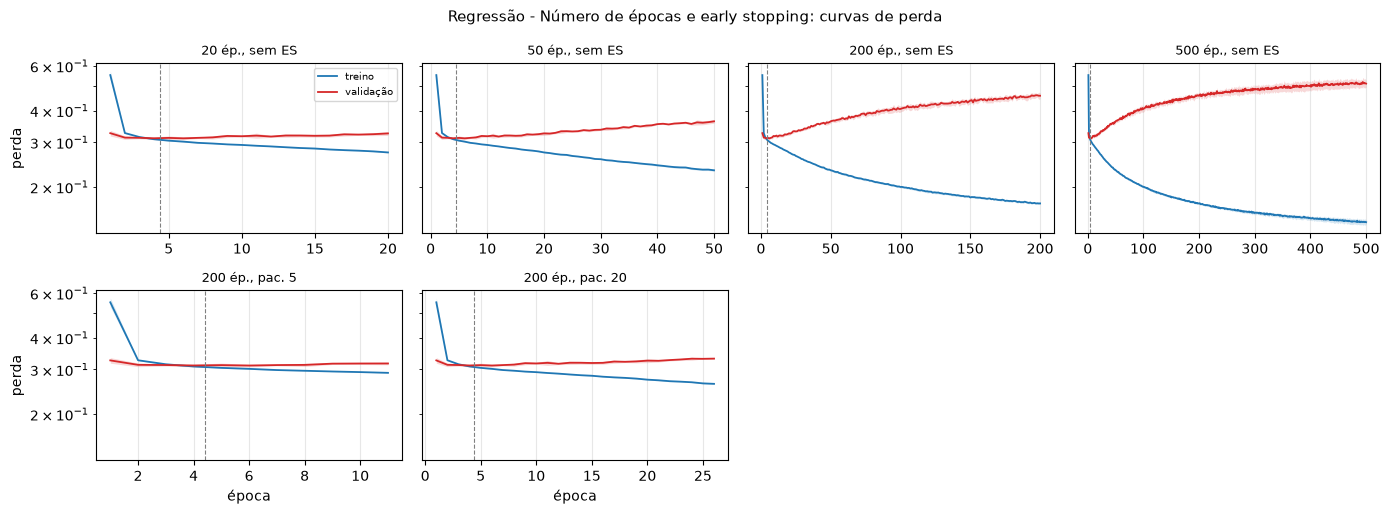

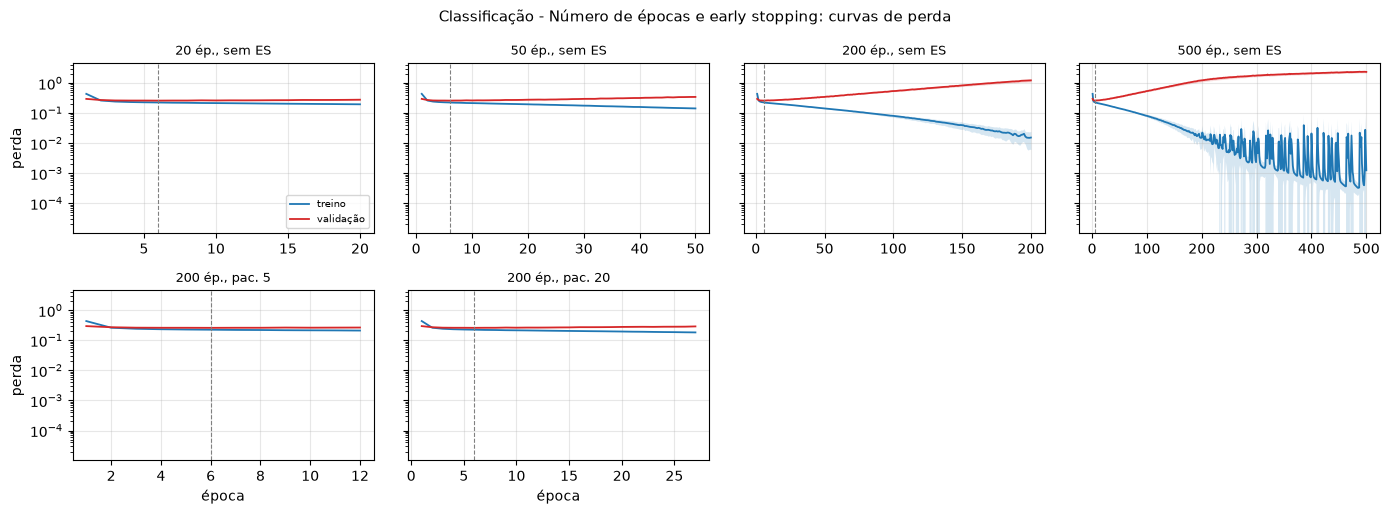

In [12]:
mostrar("epocas_es")
graficos("epocas_es", log_y=True)

### 2.8 Weight decay (opcional)


Regressão - Weight decay (L2)


,valor,parâmetros,RMSE treino,RMSE validação,gap,melhor época,épocas exec.,tempo (s)
0,0.0,2081,11.639 ± 0.158,11.844 ± 0.078,-0.2057,4.4,24.4,3.02
1,1e-05,2081,11.638 ± 0.158,11.847 ± 0.077,-0.2087,4.4,24.4,3.12
2,0.0001,2081,11.641 ± 0.156,11.844 ± 0.075,-0.2031,4.4,24.4,3.20
3,0.001,2081,11.600 ± 0.059,11.838 ± 0.072,-0.2381,4.8,24.8,3.16
4,0.01,2081,11.560 ± 0.117,11.760 ± 0.049,-0.2000,12.8,32.8,4.24



Classificação - Weight decay (L2)


,valor,parâmetros,F1 treino,F1 validação,gap,melhor época,épocas exec.,tempo (s)
0,0.0,2081,0.8532 ± 0.0025,0.8233 ± 0.0039,0.0299,6.0,26.0,3.41
1,1e-05,2081,0.8535 ± 0.0029,0.8231 ± 0.0035,0.0305,6.0,26.0,3.55
2,0.0001,2081,0.8535 ± 0.0018,0.8220 ± 0.0050,0.0315,6.0,26.0,3.57
3,0.001,2081,0.8536 ± 0.0022,0.8218 ± 0.0028,0.0318,6.0,26.0,3.61
4,0.01,2081,0.8519 ± 0.0061,0.8234 ± 0.0049,0.0285,20.2,40.2,5.61


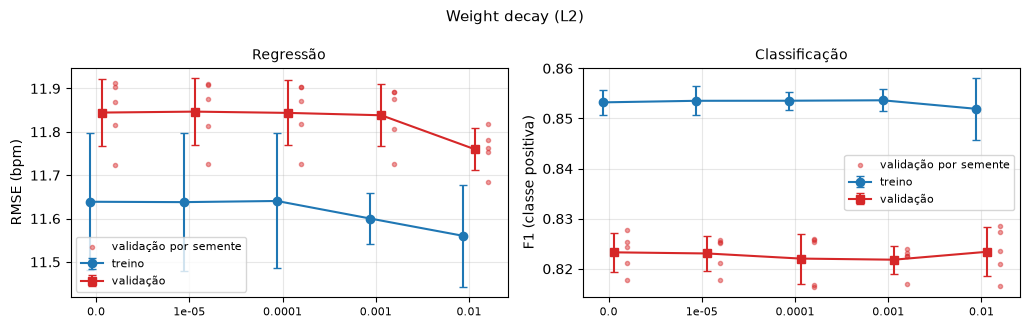

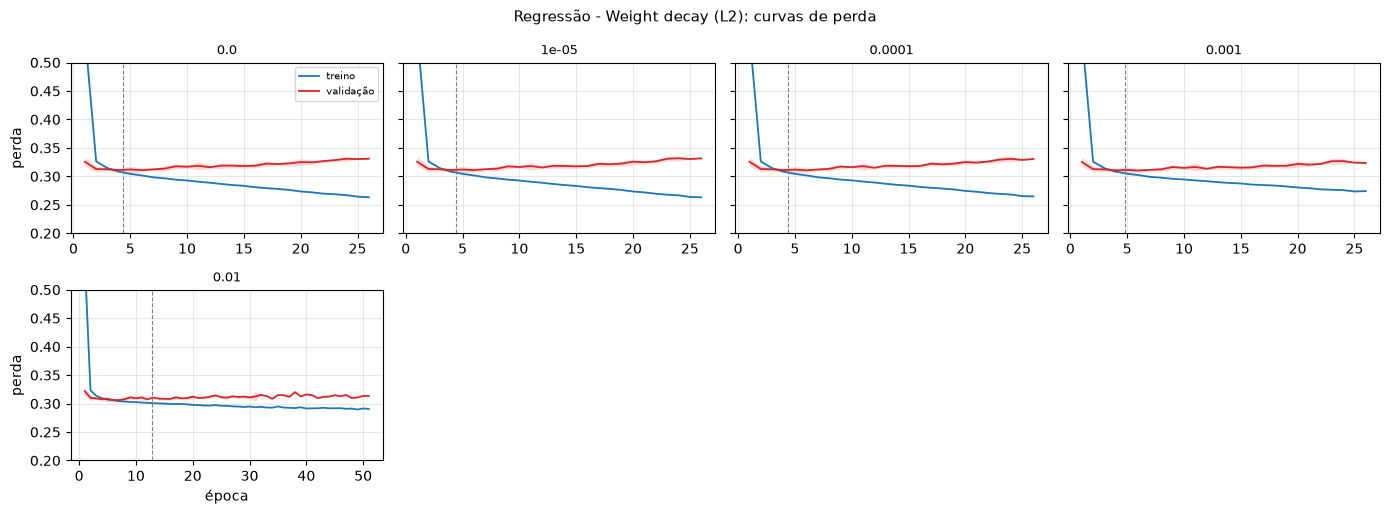

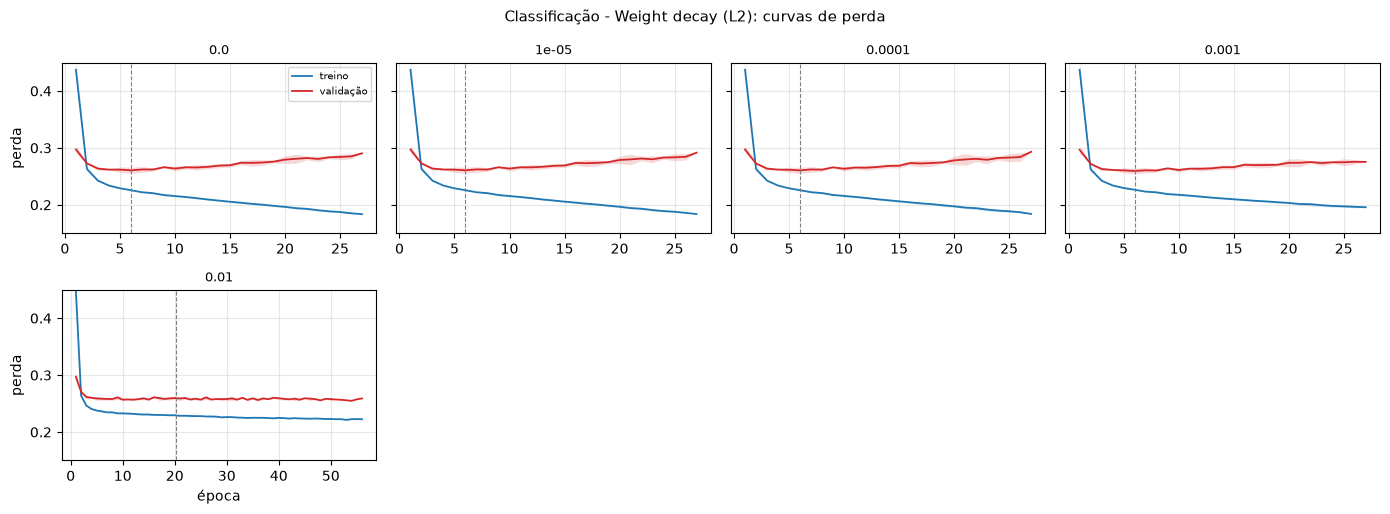

In [13]:
mostrar("weight_decay")
graficos("weight_decay", ylim_reg=(0.2, 0.5), ylim_clf=(0.15, 0.45))

### 2.9 Dropout (opcional)


Regressão - Dropout


,valor,parâmetros,RMSE treino,RMSE validação,gap,melhor época,épocas exec.,tempo (s)
0,0.0,2081,11.639 ± 0.158,11.844 ± 0.078,-0.2057,4.4,24.4,3.02
1,0.1,2081,11.524 ± 0.085,11.796 ± 0.052,-0.2716,9.6,29.6,4.27
2,0.3,2081,11.671 ± 0.122,11.746 ± 0.024,-0.0755,10.8,30.8,4.48
3,0.5,2081,11.793 ± 0.133,11.820 ± 0.026,-0.0263,17.4,37.4,5.78



Classificação - Dropout


,valor,parâmetros,F1 treino,F1 validação,gap,melhor época,épocas exec.,tempo (s)
0,0.0,2081,0.8532 ± 0.0025,0.8233 ± 0.0039,0.0299,6.0,26.0,3.41
1,0.1,2081,0.8529 ± 0.0044,0.8239 ± 0.0075,0.0290,7.2,27.2,4.12
2,0.3,2081,0.8545 ± 0.0046,0.8211 ± 0.0053,0.0334,11.0,31.0,4.66
3,0.5,2081,0.8551 ± 0.0031,0.8174 ± 0.0041,0.0378,18.8,38.8,5.96


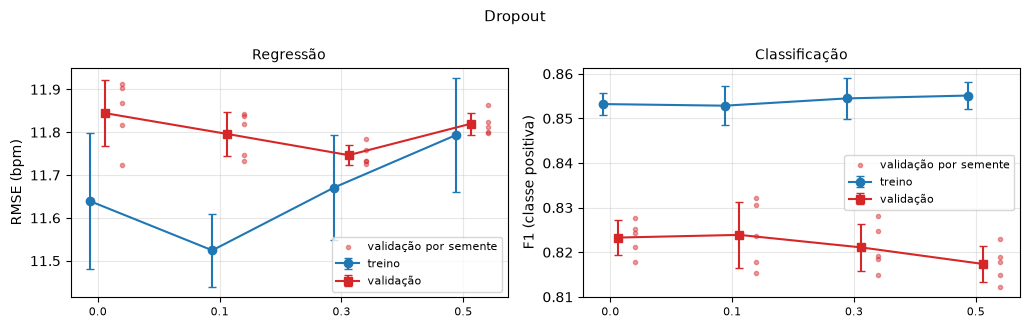

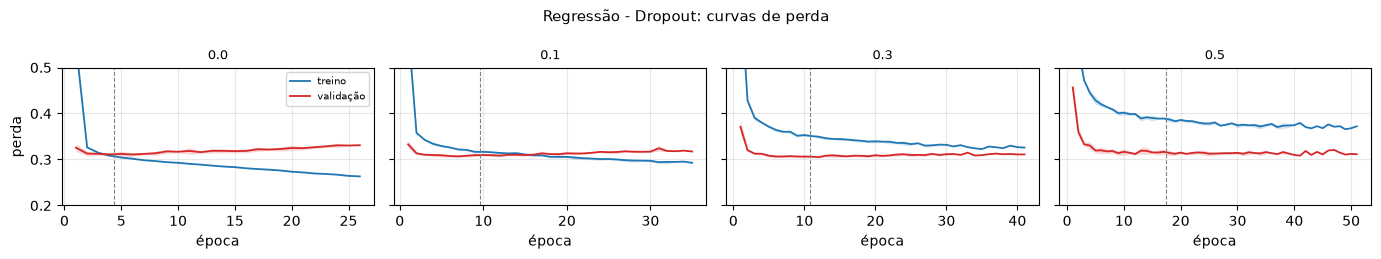

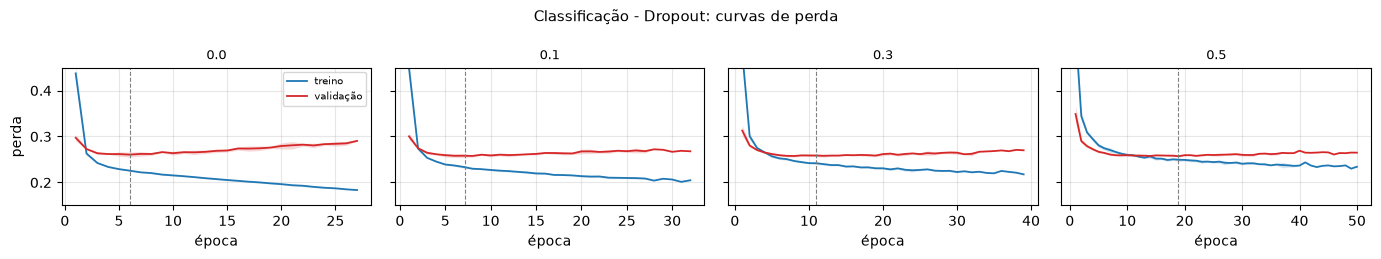

In [14]:
mostrar("dropout")
graficos("dropout", ylim_reg=(0.2, 0.5), ylim_clf=(0.15, 0.45))

A perda de treino com dropout é medida com o dropout ligado (modo `train()`), por isso fica acima da de validação
(modo `eval()`). As métricas de treino da tabela, por outro lado, são calculadas em `eval()`.

### 2.10 Função de perda (regressão) e `pos_weight` (classificação) (opcionais)


Regressão - Função de perda (regressão)


,valor,parâmetros,RMSE treino,RMSE validação,gap,melhor época,épocas exec.,tempo (s)
0,MSE,2081,11.639 ± 0.158,11.844 ± 0.078,-0.2057,4.4,24.4,3.02
1,MAE,2081,11.755 ± 0.138,11.884 ± 0.090,-0.1282,3.8,23.8,3.45
2,Huber,2081,11.697 ± 0.119,11.847 ± 0.079,-0.1493,3.4,23.4,3.23



Classificação - pos_weight da BCE (classificação)


,valor,parâmetros,F1 treino,F1 validação,gap,melhor época,épocas exec.,tempo (s)
0,1.0,2081,0.8532 ± 0.0025,0.8233 ± 0.0039,0.0299,6.0,26.0,3.41
1,1.5,2081,0.8487 ± 0.0051,0.8215 ± 0.0072,0.0272,5.0,25.0,3.41
2,2.3,2081,0.8432 ± 0.0052,0.8142 ± 0.0078,0.0291,5.8,25.8,3.47
3,3.5,2081,0.8207 ± 0.0057,0.7975 ± 0.0096,0.0232,4.4,24.4,3.24


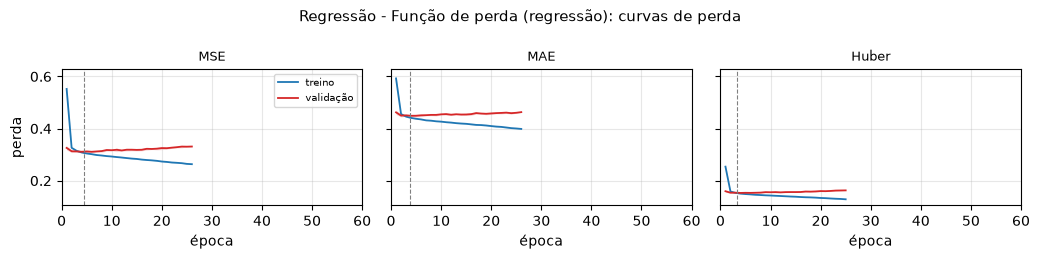

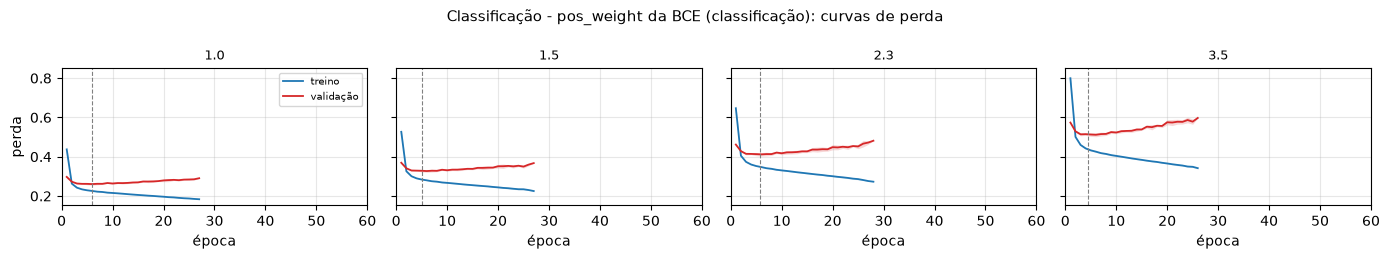

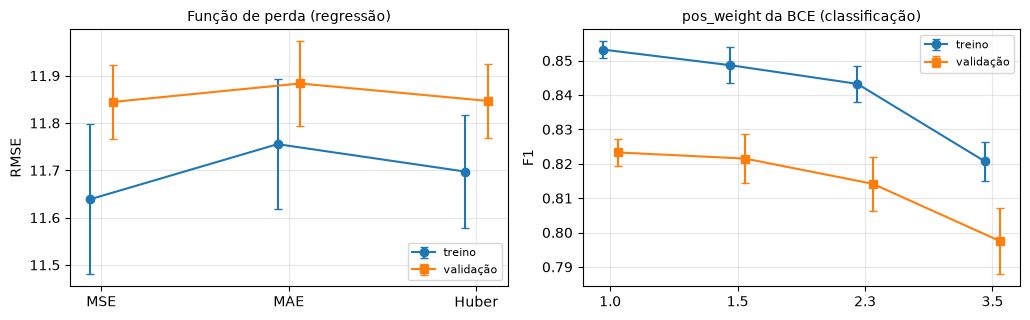

In [15]:
mostrar("perda")
mostrar("pos_weight")
for nome in ("perda", "pos_weight"):
    p = "regressao" if nome == "perda" else "classificacao"
    curvas_estudo(p, TABELAS[p][nome], f"{NOME_PROBLEMA[p]} - {TITULOS[nome]}: curvas de perda", max_epoca=60)
    salvar_fig(f"hp_{nome}_curvas_{p}")
    plt.show()
fig, axes = plt.subplots(1, 2, figsize=(10.4, 3.3))
for ax, (p, nome) in zip(axes, (("regressao", "perda"), ("classificacao", "pos_weight"))):
    t, met = TABELAS[p][nome], METRICA_PRINCIPAL[p]
    x = np.arange(len(t))
    ax.errorbar(x - 0.06, t[f"treino_{met}_media"], t[f"treino_{met}_desvio"], fmt="o-", capsize=3, label="treino")
    ax.errorbar(x + 0.06, t[f"val_{met}_media"], t[f"val_{met}_desvio"], fmt="s-", capsize=3, label="validação")
    ax.set_xticks(x, t["valor"]); ax.set_title(TITULOS[nome], fontsize=10); ax.set_ylabel(met); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.tight_layout(); salvar_fig("hp_perda_pos_weight"); plt.show()

Na classificação, o `pos_weight` desloca as probabilidades para cima. Com o limiar fixo em 0,5, isso troca precision
por recall:

In [16]:
pw = log[(log["problema"] == "classificacao") & log["chave"].isin(TABELAS["classificacao"]["pos_weight"]["chave"])]
pw = pw.assign(pos_weight=pw["cfg_pos_weight"]).groupby("pos_weight")[["val_Precision", "val_Recall", "val_F1", "val_PR-AUC", "val_ROC-AUC"]].agg(["mean", "std"])
salvar_tabela(pw.reset_index(), "hp_pos_weight_precision_recall")
pw.round(4)

val_Precision         val_Recall          val_F1          \
                    mean     std       mean     std    mean     std   
pos_weight                                                            
1.0               0.8587  0.0091     0.7908  0.0109  0.8233  0.0039   
1.5               0.8212  0.0155     0.8220  0.0050  0.8215  0.0072   
2.3               0.7742  0.0171     0.8587  0.0048  0.8142  0.0078   
3.5               0.7278  0.0145     0.8821  0.0026  0.7975  0.0096   

           val_PR-AUC         val_ROC-AUC          
                 mean     std        mean     std  
pos_weight                                         
1.0            0.9094  0.0018      0.9487  0.0012  
1.5            0.9091  0.0021      0.9487  0.0015  
2.3            0.9098  0.0015      0.9489  0.0013  
3.5            0.9087  0.0025      0.9482  0.0014

### 2.11 Padronização das features (opcional)


Regressão - Padronização das features


,valor,parâmetros,RMSE treino,RMSE validação,gap,melhor época,épocas exec.,tempo (s)
0,com StandardScaler,2081,11.639 ± 0.158,11.844 ± 0.078,-0.2057,4.4,24.4,3.02
1,sem StandardScaler,2081,12.325 ± 0.180,12.054 ± 0.191,0.2713,61.4,81.4,11.44



Classificação - Padronização das features


,valor,parâmetros,F1 treino,F1 validação,gap,melhor época,épocas exec.,tempo (s)
0,com StandardScaler,2081,0.8532 ± 0.0025,0.8233 ± 0.0039,0.0299,6.0,26.0,3.41
1,sem StandardScaler,2081,0.8249 ± 0.0029,0.8109 ± 0.0122,0.0140,63.4,83.4,11.33


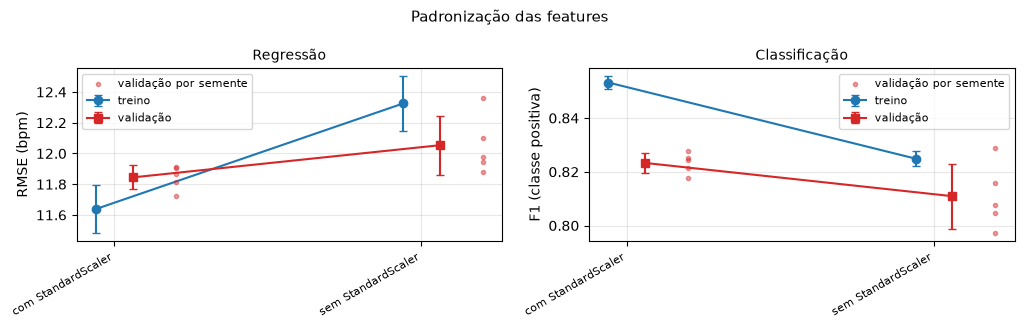

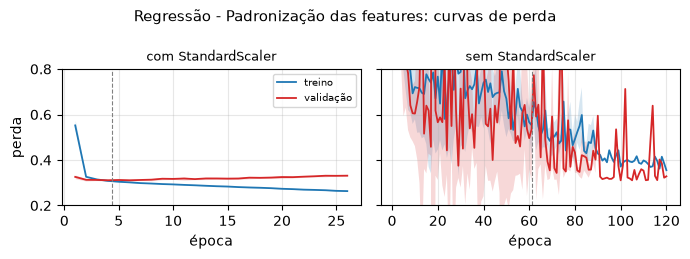

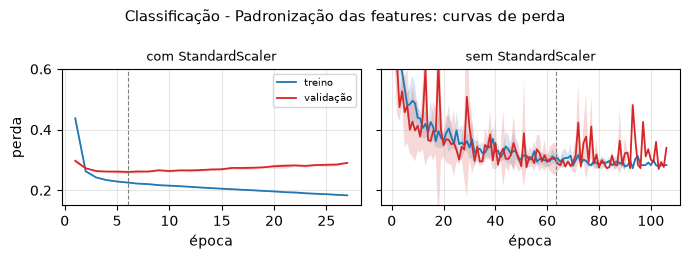

In [17]:
mostrar("padronizar")
graficos("padronizar", ylim_reg=(0.2, 0.8), ylim_clf=(0.15, 0.6))

## 3. Interação entre hiperparâmetros: mapas de calor

Duas varreduras 2D com 3 sementes cada: **taxa de aprendizado × tamanho do batch** e **neurônios × weight decay**
(os demais hiperparâmetros no baseline).

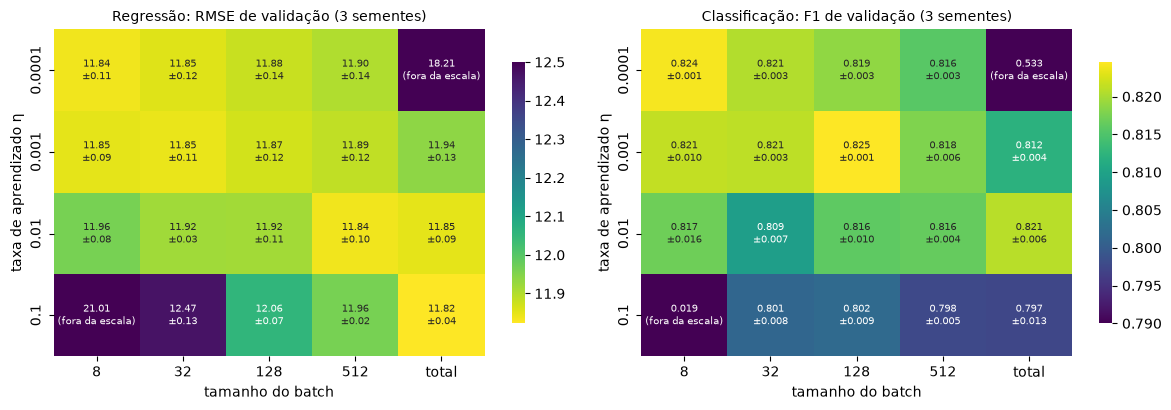

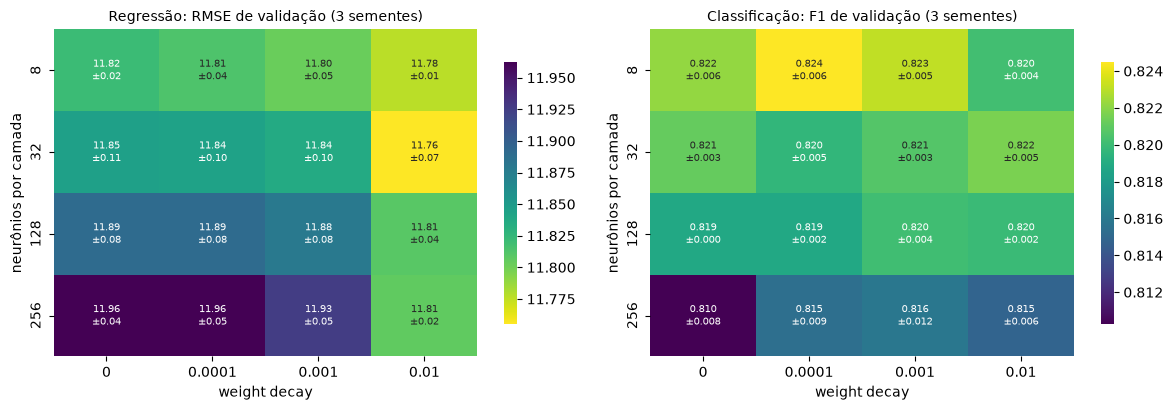

In [18]:
def grade(p, nome):
    p1, v1, p2, v2 = GRADES_2D[nome]
    t = resumir(p, tarefas_grade(nome), log, SEMENTES[:3])
    met = METRICA_PRINCIPAL[p]
    media = np.array([[t.set_index("valor").loc[f"{a}|{b}", f"val_{met}_media"] for b in v2] for a in v1])
    desvio = np.array([[t.set_index("valor").loc[f"{a}|{b}", f"val_{met}_desvio"] for b in v2] for a in v1])
    ep = np.array([[t.set_index("valor").loc[f"{a}|{b}", "melhor_epoca_media"] for b in v2] for a in v1])
    salvar_tabela(t, f"grade_{nome}_{p}")
    return media, desvio, ep, v1, v2

ROTULOS = {"batch": lambda v: "total" if v == 5760 else str(v), "lr": lambda v: f"{v:g}",
           "neuronios": str, "weight_decay": lambda v: f"{v:g}"}
EIXOS = {"lr": "taxa de aprendizado η", "batch": "tamanho do batch", "neuronios": "neurônios por camada",
         "weight_decay": "weight decay"}
for nome in GRADES_2D:
    p1, _, p2, _ = GRADES_2D[nome]
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for ax, p in zip(axes, PROBLEMAS):
        media, desvio, ep, v1, v2 = grade(p, nome)
        met = METRICA_PRINCIPAL[p]
        cmap = "viridis_r" if met == "RMSE" else "viridis"
        if nome == "lr_x_batch":   # escala de cor limitada para não ser dominada pelas células que falharam
            vmin, vmax = (11.75, 12.5) if met == "RMSE" else (0.79, 0.83)
            media_plot = np.clip(media, vmin, vmax)
        else:
            media_plot = media
        mapa_calor(media_plot, desvio, [ROTULOS[p1](v) for v in v1], [ROTULOS[p2](v) for v in v2],
                   EIXOS[p2], EIXOS[p1], f"{NOME_PROBLEMA[p]}: {met} de validação (3 sementes)", cmap, ax=ax,
                   casas=2 if met == "RMSE" else 3)
        # anotação com o valor real nas células recortadas
        for i in range(media.shape[0]):
            for j in range(media.shape[1]):
                if media_plot[i, j] != media[i, j]:
                    ax.texts[i * media.shape[1] + j].set_text(f"{media[i, j]:.2f}\n(fora da escala)" if met == "RMSE" else f"{media[i, j]:.3f}\n(fora da escala)")
    fig.tight_layout()
    salvar_fig(f"mapa_calor_{nome}")
    plt.show()

Época média do melhor estado na varredura η × batch (classificação). Mostra que o número de **atualizações**
necessárias, e não o de épocas, é o que importa:

In [19]:
media, desvio, ep, v1, v2 = grade("classificacao", "lr_x_batch")
pd.DataFrame(ep, index=[f"η={v:g}" for v in v1], columns=[f"batch {ROTULOS['batch'](b)}" for b in v2]).round(1)

,batch 8,batch 32,batch 128,batch 512,batch total
η=0.0001,26.3,45.3,97.0,200.0,200.0
η=0.001,3.7,6.0,12.3,29.3,200.0
η=0.01,5.3,2.3,4.3,6.3,37.0
η=0.1,5.3,7.7,4.3,5.0,24.0


## 4. Tabela de sensibilidade

Hiperparâmetros ordenados pela amplitude do efeito na validação (diferença entre o melhor e o pior valor testado).
O efeito é classificado como **relevante** se as 5 sementes do melhor valor diferem das 5 do pior pelo teste de
Mann-Whitney (p < 0,05), e **desprezível** caso contrário, porque a diferença cabe na variação entre sementes.

In [20]:
SENS = {}
for p in PROBLEMAS:
    SENS[p] = sensibilidade(p, TABELAS[p], log)
    salvar_tabela(SENS[p], f"sensibilidade_{p}")
    print(NOME_PROBLEMA[p])
    display(SENS[p].round(4))

Regressão


,hiperparametro,melhor_valor,melhor_val_RMSE,desvio_melhor,pior_valor,pior_val_RMSE,desvio_pior,amplitude,p_mann_whitney,efeito
0,lr,0.0001,11.8430,0.0891,1.0,33.8614,26.3236,22.0184,0.0079,relevante
1,epocas_es,"200 ép., pac. 20",11.8444,0.0776,"500 ép., sem ES",15.2345,0.2852,3.3901,0.0079,relevante
2,neuronios,4,11.7243,0.0408,2,13.5381,4.1780,1.8138,0.3095,desprezível
3,padronizar,com StandardScaler,11.8444,0.0776,sem StandardScaler,12.0537,0.1913,0.2093,0.0317,relevante
4,ativacao,Sigmoid,11.7012,0.0165,ReLU,11.8444,0.0776,0.1432,0.0079,relevante
5,camadas,1,11.7582,0.0495,5,11.8897,0.1054,0.1315,0.0556,desprezível
6,dropout,0.3,11.7465,0.0237,0.0,11.8444,0.0776,0.0980,0.1508,desprezível
7,weight_decay,0.01,11.7601,0.0488,1e-05,11.8466,0.0774,0.0865,0.1508,desprezível
8,batch,32,11.8444,0.0776,total,11.9231,0.0941,0.0787,0.2222,desprezível
9,perda,MSE,11.8444,0.0776,MAE,11.8835,0.0898,0.0391,0.3095,desprezível


Classificação


,hiperparametro,melhor_valor,melhor_val_F1,desvio_melhor,pior_valor,pior_val_F1,desvio_pior,amplitude,p_mann_whitney,efeito
0,lr,0.001,0.8233,0.0039,1.0,0.0018,0.0041,0.8215,0.0097,relevante
1,neuronios,32,0.8233,0.0039,2,0.6560,0.3667,0.1673,0.1732,desprezível
2,epocas_es,"200 ép., pac. 5",0.8233,0.0039,"500 ép., sem ES",0.7569,0.0107,0.0664,0.0079,relevante
3,pos_weight,1.0,0.8233,0.0039,3.5,0.7975,0.0096,0.0258,0.0079,relevante
4,padronizar,com StandardScaler,0.8233,0.0039,sem StandardScaler,0.8109,0.0122,0.0124,0.1508,desprezível
5,batch,32,0.8233,0.0039,total,0.8119,0.0053,0.0114,0.0159,relevante
6,otimizador,AdamW,0.8234,0.0025,SGD,0.8132,0.0034,0.0101,0.0119,relevante
7,dropout,0.1,0.8239,0.0075,0.5,0.8174,0.0041,0.0065,0.2222,desprezível
8,camadas,2,0.8233,0.0039,3,0.8171,0.0042,0.0062,0.0556,desprezível
9,ativacao,Sigmoid,0.8251,0.0034,GELU,0.8221,0.0055,0.0031,0.5476,desprezível


### Referência linear

Como na regressão quase todas as configurações ficaram numa faixa estreita de RMSE, vale comparar com um modelo
linear ajustado nos mesmos dados (mesmo treino, mesma padronização, avaliado na validação). Ele não faz parte do
estudo; serve para medir quanto da relação entre features e target é não linear.

In [21]:
from sklearn.linear_model import LinearRegression, LogisticRegression
d_reg, d_clf = preparar("regressao"), preparar("classificacao")
lin = LinearRegression().fit(d_reg.X_tr, d_reg.y_tr_orig)
logi = LogisticRegression(max_iter=5000).fit(d_clf.X_tr, d_clf.y_tr_orig)
ref_linear = pd.DataFrame([
    {"problema": "regressao", "modelo": "Regressão linear (OLS)",
     "treino": metricas_regressao(d_reg.y_tr_orig, lin.predict(d_reg.X_tr))["RMSE"],
     "validação": metricas_regressao(d_reg.y_val_orig, lin.predict(d_reg.X_val))["RMSE"]},
    {"problema": "classificacao", "modelo": "Regressão logística",
     "treino": metricas_classificacao(d_clf.y_tr_orig, logi.predict(d_clf.X_tr))["F1"],
     "validação": metricas_classificacao(d_clf.y_val_orig, logi.predict(d_clf.X_val))["F1"]},
])
salvar_tabela(ref_linear, "referencia_linear_validacao")
ref_linear.round(4)

,problema,modelo,treino,validação
0,regressao,Regressão linear (OLS),11.8358,11.6103
1,classificacao,Regressão logística,0.8389,0.8237


## 5. Busca aleatória final

O espaço de busca combina o que os estudos isolados mostraram: só faixas que funcionaram (η entre 10⁻⁴ e 10⁻² em
escala log, batches pequenos e médios, até 3 camadas, otimizadores adaptativos ou SGD com momentum), mais a
regularização (weight decay, dropout) e, na regressão, funções suaves e redes pequenas, que foram as melhores.
30 configurações por problema, sorteadas com semente fixa, 3 sementes cada. As 3 melhores (e o baseline) recebem
depois as sementes 3 e 4, e a escolha final é pela média das 5 sementes na validação.

In [22]:
ESPACO = {
    "regressao": {"neuronios": [4, 8, 16, 32, 64], "camadas": [1, 2, 3],
                  "ativacao": ["ReLU", "LeakyReLU", "Tanh", "Sigmoid", "ELU", "GELU"],
                  "otimizador": ["Adam", "AdamW", "RMSprop", "SGD_momentum"], "lr": (1e-4, 1e-2),
                  "batch": [16, 32, 64, 128, 256], "weight_decay": [0.0, 1e-4, 1e-3, 1e-2],
                  "dropout": [0.0, 0.1, 0.2, 0.3], "perda": ["MSE", "Huber"]},
    "classificacao": {"neuronios": [8, 16, 32, 64, 128], "camadas": [1, 2, 3],
                      "ativacao": ["ReLU", "LeakyReLU", "Tanh", "Sigmoid", "ELU", "GELU"],
                      "otimizador": ["Adam", "AdamW", "RMSprop", "SGD_momentum"], "lr": (1e-4, 3e-3),
                      "batch": [8, 16, 32, 64, 128], "weight_decay": [0.0, 1e-5, 1e-4, 1e-3, 1e-2],
                      "dropout": [0.0, 0.1, 0.2, 0.3], "pos_weight": [1.0, 1.25, 1.5]},
}
N_CONFIGS = 30

def sortear(p, n=N_CONFIGS, seed=2026):
    rng = np.random.default_rng(seed)
    cfgs = []
    for _ in range(n):
        alt = {}
        for k, v in ESPACO[p].items():
            if isinstance(v, tuple):  # log-uniforme
                alt[k] = float(f"{10 ** rng.uniform(np.log10(v[0]), np.log10(v[1])):.2e}")
            else:
                alt[k] = v[rng.integers(len(v))]
                alt[k] = alt[k].item() if hasattr(alt[k], "item") else alt[k]
        cfgs.append(montar_cfg(alt))
    return cfgs

BUSCA = {p: sortear(p) for p in PROBLEMAS}
rodar([(p, c, s) for p in PROBLEMAS for c in BUSCA[p] for s in SEMENTES[:3]])
log = carregar_log()

180 tarefas, 180 já registradas, 0 a executar


In [23]:
def resumo_busca(p, cfgs, sementes):
    met = METRICA_PRINCIPAL[p]
    linhas = []
    for i, c in enumerate(cfgs):
        r = log[(log["problema"] == p) & (log["chave"] == chave_cfg(c)) & log["seed"].isin(sementes)]
        linhas.append({"id": i, **{k: c[k] for k in ESPACO[p]}, "n_parametros": int(r["n_parametros"].iloc[0]),
                       "n_sementes": len(r), f"treino_{met}": r[f"treino_{met}"].mean(),
                       f"val_{met}": r[f"val_{met}"].mean(), "desvio": r[f"val_{met}"].std(),
                       "melhor_epoca": r["melhor_epoca"].mean(), "tempo_s": r["tempo_treino_s"].mean(),
                       "chave": chave_cfg(c)})
    return pd.DataFrame(linhas).sort_values(f"val_{met}", ascending=(met == "RMSE")).reset_index(drop=True)

RES_BUSCA = {}
for p in PROBLEMAS:
    RES_BUSCA[p] = resumo_busca(p, BUSCA[p], SEMENTES[:3])
    salvar_tabela(RES_BUSCA[p], f"busca_aleatoria_{p}")
    print(NOME_PROBLEMA[p], "- 30 configurações, 3 sementes (ordenadas pela validação)")
    display(RES_BUSCA[p].drop(columns="chave").round(4))

Regressão - 30 configurações, 3 sementes (ordenadas pela validação)


,id,neuronios,camadas,ativacao,otimizador,lr,batch,weight_decay,dropout,perda,n_parametros,n_sementes,treino_RMSE,val_RMSE,desvio,melhor_epoca,tempo_s
0,21,8,1,LeakyReLU,RMSprop,0.0052,32,0.0010,0.3,MSE,257,3,11.8665,11.6836,0.0137,19.0000,3.9648
1,28,32,2,Sigmoid,AdamW,0.0002,16,0.0001,0.1,Huber,2081,3,11.7820,11.6840,0.0033,96.6667,35.3504
2,23,8,1,Tanh,Adam,0.0013,64,0.0000,0.3,Huber,257,3,11.8946,11.6941,0.0049,55.6667,4.3525
3,7,16,3,ELU,RMSprop,0.0007,64,0.0100,0.0,MSE,1057,3,11.8150,11.6989,0.0133,36.6667,4.0079
4,9,16,2,Tanh,RMSprop,0.0002,16,0.0010,0.3,Huber,785,3,11.8774,11.7036,0.0048,104.6667,32.0611
5,1,64,3,ELU,SGD_momentum,0.0002,256,0.0010,0.0,MSE,10369,3,11.8685,11.7102,0.0394,195.3333,5.2566
6,29,8,1,ReLU,Adam,0.0005,128,0.0000,0.3,MSE,257,3,11.8935,11.7106,0.0157,93.6667,3.5339
7,3,32,3,Sigmoid,AdamW,0.0005,16,0.0001,0.0,MSE,3137,3,11.7730,11.7137,0.0177,45.0000,20.7757
8,24,64,2,GELU,SGD_momentum,0.0005,128,0.0001,0.3,MSE,6209,3,11.7946,11.7187,0.0464,132.6667,7.4115
9,0,64,1,ReLU,RMSprop,0.0009,16,0.0001,0.2,MSE,2049,3,11.6054,11.7198,0.0186,5.0000,5.0589


Classificação - 30 configurações, 3 sementes (ordenadas pela validação)


,id,neuronios,camadas,ativacao,otimizador,lr,batch,weight_decay,dropout,pos_weight,n_parametros,n_sementes,treino_F1,val_F1,desvio,melhor_epoca,tempo_s
0,25,8,1,Tanh,RMSprop,0.0016,16,0.0001,0.1,1.25,257,3,0.8423,0.8259,0.0036,10.3333,6.8005
1,20,64,3,Tanh,Adam,0.0008,8,0.0001,0.0,1.50,10369,3,0.8414,0.8258,0.0041,5.3333,17.6015
2,14,16,2,Sigmoid,AdamW,0.0014,32,0.0100,0.3,1.50,785,3,0.8441,0.8255,0.0037,56.3333,12.6186
3,10,32,2,ReLU,AdamW,0.0004,64,0.0001,0.3,1.25,2081,3,0.8525,0.8248,0.0029,28.0000,4.1991
4,13,32,3,Tanh,Adam,0.0003,64,0.0010,0.2,1.00,3137,3,0.8411,0.8236,0.0016,55.0000,8.0979
5,3,64,3,Sigmoid,AdamW,0.0003,8,0.0000,0.0,1.00,10369,3,0.8478,0.8235,0.0039,62.3333,59.2808
6,26,8,3,GELU,RMSprop,0.0013,32,0.0100,0.0,1.00,401,3,0.8422,0.8231,0.0046,15.6667,6.7943
7,23,16,1,Tanh,Adam,0.0007,32,0.0000,0.3,1.25,513,3,0.8415,0.8226,0.0009,29.3333,6.1480
8,27,32,2,ELU,RMSprop,0.0018,128,0.0000,0.2,1.50,2081,3,0.8459,0.8225,0.0013,28.3333,2.1395
9,7,32,3,ELU,RMSprop,0.0004,32,0.0100,0.0,1.00,3137,3,0.8400,0.8224,0.0046,22.6667,7.2322


In [24]:
FINALISTAS = {}
for p in PROBLEMAS:
    top = [BUSCA[p][i] for i in RES_BUSCA[p]["id"].head(3)]
    FINALISTAS[p] = top + [dict(BASELINE)]
rodar([(p, c, s) for p in PROBLEMAS for c in FINALISTAS[p] for s in SEMENTES])
log = carregar_log()
ESCOLHA = {}
for p in PROBLEMAS:
    met = METRICA_PRINCIPAL[p]
    linhas = []
    for i, c in enumerate(FINALISTAS[p]):
        r = log[(log["problema"] == p) & (log["chave"] == chave_cfg(c)) & log["seed"].isin(SEMENTES)]
        linhas.append({"candidato": "baseline" if i == 3 else f"busca #{i + 1}",
                       **{k: c[k] for k in ESPACO[p]}, "n_parametros": int(r["n_parametros"].iloc[0]),
                       f"treino_{met}": r[f"treino_{met}"].mean(), f"val_{met}": r[f"val_{met}"].mean(),
                       "desvio": r[f"val_{met}"].std(), "melhor_epoca": r["melhor_epoca"].mean()})
    fin = pd.DataFrame(linhas)
    i_best = fin[f"val_{met}"].idxmin() if met == "RMSE" else fin[f"val_{met}"].idxmax()
    ESCOLHA[p] = FINALISTAS[p][i_best]
    salvar_tabela(fin, f"finalistas_{p}")
    print(NOME_PROBLEMA[p], "- finalistas com 5 sementes; escolhido:", fin.loc[i_best, "candidato"])
    display(fin.round(4))

40 tarefas, 40 já registradas, 0 a executar
Regressão - finalistas com 5 sementes; escolhido: busca #2


,candidato,neuronios,camadas,ativacao,otimizador,lr,batch,weight_decay,dropout,perda,n_parametros,treino_RMSE,val_RMSE,desvio,melhor_epoca
0,busca #1,8,1,LeakyReLU,RMSprop,0.0052,32,0.0010,0.3,MSE,257,11.8825,11.6931,0.0190,17.2
1,busca #2,32,2,Sigmoid,AdamW,0.0002,16,0.0001,0.1,Huber,2081,11.7819,11.6813,0.0054,103.6
2,busca #3,8,1,Tanh,Adam,0.0013,64,0.0000,0.3,Huber,257,11.8931,11.7005,0.0143,45.2
3,baseline,32,2,ReLU,Adam,0.0010,32,0.0000,0.0,MSE,2081,11.6388,11.8444,0.0776,4.4


Classificação - finalistas com 5 sementes; escolhido: busca #1


,candidato,neuronios,camadas,ativacao,otimizador,lr,batch,weight_decay,dropout,pos_weight,n_parametros,treino_F1,val_F1,desvio,melhor_epoca
0,busca #1,8,1,Tanh,RMSprop,0.0016,16,0.0001,0.1,1.25,257,0.8415,0.8267,0.0038,8.4
1,busca #2,64,3,Tanh,Adam,0.0008,8,0.0001,0.0,1.50,10369,0.8402,0.8249,0.0032,5.4
2,busca #3,16,2,Sigmoid,AdamW,0.0014,32,0.0100,0.3,1.50,785,0.8444,0.8259,0.0027,57.8
3,baseline,32,2,ReLU,Adam,0.0010,32,0.0000,0.0,1.00,2081,0.8532,0.8233,0.0039,6.0


## 6. Configuração final: treino, limiar e salvamento

A configuração escolhida é treinada com as 5 sementes. O modelo salvo é o da semente com melhor métrica de
validação. Na classificação, o limiar de decisão é escolhido **na validação**, maximizando o F1 (grade de 0,05 a
0,95, passo 0,01).

In [25]:
def melhor_limiar(y, prob):
    grade_l = np.round(np.arange(0.05, 0.96, 0.01), 2)
    f1s = [metricas_classificacao(y, (prob >= t).astype(int))["F1"] for t in grade_l]
    return float(grade_l[int(np.argmax(f1s))]), float(max(f1s))

FINAL = {}
for p in PROBLEMAS:
    dados = preparar(p)
    cfg = ESCOLHA[p]
    met = METRICA_PRINCIPAL[p]
    rodadas = []
    for s in SEMENTES:
        r, h, m = executar(cfg, dados, s, retornar_modelo=True)
        lim = 0.5
        if p == "classificacao":
            prob_val = 1 / (1 + np.exp(-prever(m, dados.X_val)))
            lim, f1_lim = melhor_limiar(dados.y_val_orig, prob_val)
        rodadas.append({"seed": s, "res": r, "hist": h, "modelo": m, "limiar": lim})
    vals = [x["res"][f"val_{met}"] for x in rodadas]
    i_best = int(np.argmin(vals) if met == "RMSE" else np.argmax(vals))
    FINAL[p] = {"cfg": cfg, "dados": dados, "rodadas": rodadas, "i": i_best}
    print(f"{NOME_PROBLEMA[p]}: {met} de validação por semente = {np.round(vals, 4)} -> semente {SEMENTES[i_best]}")
    print("Configuração final:", json.dumps(cfg))

Regressão: RMSE de validação por semente = [11.6868 11.6849 11.6803 11.6727 11.682 ] -> semente 3
Configuração final: {"neuronios": 32, "camadas": 2, "ativacao": "Sigmoid", "otimizador": "AdamW", "lr": 0.00016, "batch": 16, "epocas": 200, "paciencia": 20, "weight_decay": 0.0001, "dropout": 0.1, "perda": "Huber", "pos_weight": 1.0, "padronizar": true}


Classificação: F1 de validação por semente = [0.8288 0.827  0.8219 0.8242 0.8316] -> semente 4
Configuração final: {"neuronios": 8, "camadas": 1, "ativacao": "Tanh", "otimizador": "RMSprop", "lr": 0.00162, "batch": 16, "epocas": 200, "paciencia": 20, "weight_decay": 0.0001, "dropout": 0.1, "perda": "MSE", "pos_weight": 1.25, "padronizar": true}


Efeito do limiar na validação, para o modelo salvo de classificação:

In [26]:
f = FINAL["classificacao"]
x = f["rodadas"][f["i"]]
prob_val = 1 / (1 + np.exp(-prever(x["modelo"], f["dados"].X_val)))
tab_lim = pd.DataFrame([{"limiar": t, **metricas_classificacao(f["dados"].y_val_orig, (prob_val >= t).astype(int))}
                        for t in sorted({0.3, 0.4, 0.5, 0.6, x["limiar"]})])
salvar_tabela(tab_lim, "limiar_validacao")
print("Limiar escolhido na validação:", x["limiar"])
tab_lim.round(4)

Limiar escolhido na validação: 0.5


,limiar,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,0.3,0.8757,0.7555,0.8716,0.8094,NaN,NaN
1,0.4,0.8910,0.8066,0.8417,0.8238,NaN,NaN
2,0.5,0.9007,0.8547,0.8096,0.8316,NaN,NaN
3,0.6,0.8986,0.8836,0.7661,0.8206,NaN,NaN


### Salvamento dos checkpoints e das saídas de referência

Antes de salvar, as saídas brutas do modelo em memória na validação e no teste são guardadas em
`logs/saidas_em_memoria_<problema>.pt`, junto com a métrica principal no teste. Elas servem para a verificação de
fidelidade do notebook 06, feita num kernel limpo. **É aqui que o teste é consultado pela primeira vez**, com a
configuração e o limiar já congelados.

In [27]:
df_ids = ler_dataset("regressao")
idx_tr, idx_val, idx_te, _ = indices_split(df_ids)
ids_val = torch.tensor(df_ids.loc[idx_val, "patient_id"].to_numpy())
ids_te = torch.tensor(df_ids.loc[idx_te, "patient_id"].to_numpy())

for p in PROBLEMAS:
    f = FINAL[p]
    x = f["rodadas"][f["i"]]
    m, dados = x["modelo"], f["dados"]
    saida_val = torch.tensor(prever(m, dados.X_val))
    saida_te = torch.tensor(prever(m, dados.X_te))
    m_te = avaliar(m, dados, dados.X_te, dados.y_te_orig, limiar=x["limiar"])
    met = METRICA_PRINCIPAL[p]
    torch.save({"ids_val": ids_val, "ids_teste": ids_te, "saida_val": saida_val, "saida_teste": saida_te,
                "metrica": met, "metrica_teste": float(m_te[met])}, LOGS / f"saidas_em_memoria_{p}.pt")
    caminho = MODELS / f"modelo_{p}.pt"
    salvar_checkpoint(m, f["cfg"], dados, caminho, limiar=x["limiar"],
                      extras={"seed": SEMENTES[f["i"]], "melhor_epoca": x["res"]["melhor_epoca"],
                              "historico": x["hist"],
                              "metricas_validacao": {k[4:]: float(v) for k, v in x["res"].items() if k.startswith("val_") and np.isfinite(v)}})
    # verificação imediata: carregar do arquivo e comparar com o modelo em memória
    m2, ck2 = inference.carregar(caminho)
    with torch.inference_mode():
        s2 = m2(torch.tensor(dados.X_te)).squeeze(1)
    print(f"{p}: salvo em {caminho.name} | {met} teste (em memória) = {m_te[met]:.4f} | "
          f"allclose após recarregar: {torch.allclose(s2, saida_te, atol=1e-6)} | dif. máx = {(s2 - saida_te).abs().max().item():.2e}")

regressao: salvo em modelo_regressao.pt | RMSE teste (em memória) = 12.1641 | allclose após recarregar: True | dif. máx = 0.00e+00
classificacao: salvo em modelo_classificacao.pt | F1 teste (em memória) = 0.8216 | allclose após recarregar: True | dif. máx = 0.00e+00


### Variação entre sementes no teste

Com a configuração congelada, as 5 sementes também são avaliadas no teste (cada uma com seu próprio limiar
escolhido na validação). Isso não muda nenhuma escolha; serve para relatar o desempenho esperado da configuração
como média ± desvio, e não só o da semente salva.

In [28]:
for p in PROBLEMAS:
    f = FINAL[p]
    linhas = []
    for x in f["rodadas"]:
        m_te = avaliar(x["modelo"], f["dados"], f["dados"].X_te, f["dados"].y_te_orig, limiar=x["limiar"])
        linhas.append({"seed": x["seed"], "salvo": x["seed"] == SEMENTES[f["i"]], "limiar": x["limiar"],
                       "melhor_epoca": x["res"]["melhor_epoca"], f"val_{METRICA_PRINCIPAL[p]}": x["res"][f"val_{METRICA_PRINCIPAL[p]}"], **m_te})
    t = pd.DataFrame(linhas)
    salvar_tabela(t, f"final_sementes_teste_{p}")
    print(NOME_PROBLEMA[p])
    display(t.round(4))
    display(t.drop(columns=["seed", "salvo"]).agg(["mean", "std"]).round(4))

Regressão


,seed,salvo,limiar,melhor_epoca,val_RMSE,MAE,MSE,RMSE,MAPE (%),R2,MedAE
0,0,False,0.5,94,11.6868,9.6496,147.7568,12.1555,6.0518,0.6783,8.0854
1,1,False,0.5,89,11.6849,9.6516,147.8031,12.1574,6.0552,0.6782,8.0558
2,2,False,0.5,107,11.6803,9.6473,147.9602,12.1639,6.0490,0.6778,8.0972
3,3,True,0.5,121,11.6727,9.6651,147.9651,12.1641,6.0597,0.6778,8.1303
4,4,False,0.5,107,11.6820,9.6649,148.2635,12.1763,6.0659,0.6772,8.1418


,limiar,melhor_epoca,val_RMSE,MAE,MSE,RMSE,MAPE (%),R2,MedAE
mean,0.5,103.6000,11.6813,9.6557,147.9497,12.1635,6.0563,0.6778,8.1021
std,0.0,12.5618,0.0054,0.0086,0.1984,0.0082,0.0067,0.0004,0.0347


Classificação


,seed,salvo,limiar,melhor_epoca,val_F1,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,0,False,0.50,14,0.8288,0.8889,0.8236,0.8055,0.8145,0.9490,0.9070
1,1,False,0.53,12,0.8270,0.8939,0.8444,0.7963,0.8196,0.9488,0.9063
2,2,False,0.51,5,0.8219,0.8967,0.8432,0.8092,0.8258,0.9502,0.9093
3,3,False,0.52,8,0.8242,0.8922,0.8293,0.8110,0.8200,0.9496,0.9066
4,4,True,0.50,3,0.8316,0.8933,0.8324,0.8110,0.8216,0.9503,0.9093


,limiar,melhor_epoca,val_F1,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
mean,0.512,8.4000,0.8267,0.8930,0.8346,0.8066,0.8203,0.9496,0.9077
std,0.013,4.6152,0.0038,0.0028,0.0090,0.0062,0.0041,0.0007,0.0015


### Configurações finais e amostras de exemplo para a inferência

In [29]:
cfgs_finais = pd.DataFrame({p: FINAL[p]["cfg"] for p in PROBLEMAS})
cfgs_finais.loc["semente salva"] = [SEMENTES[FINAL[p]["i"]] for p in PROBLEMAS]
cfgs_finais.loc["limiar"] = ["-", FINAL["classificacao"]["rodadas"][FINAL["classificacao"]["i"]]["limiar"]]
salvar_tabela(cfgs_finais.reset_index().rename(columns={"index": "hiperparâmetro"}), "config_final")
display(cfgs_finais)

# 5 pacientes do teste, com as colunas originais do dataset, para demonstrar a inferência (notebook 06 e README)
bruto = pd.read_csv(ROOT / "data" / "processed" / "dataset_classification.csv")
(ROOT / "exemplos").mkdir(exist_ok=True)
bruto.set_index("patient_id").loc[ids_te[:5].tolist()].reset_index().to_csv(ROOT / "exemplos" / "novas_amostras.csv", index=False)
print("exemplos/novas_amostras.csv:", ids_te[:5].tolist())

,regressao,classificacao
neuronios,32,8
camadas,2,1
ativacao,Sigmoid,Tanh
otimizador,AdamW,RMSprop
lr,0.00016,0.00162
batch,16,16
epocas,200,200
paciencia,20,20
weight_decay,0.0001,0.0001
dropout,0.1,0.1


exemplos/novas_amostras.csv: [7798, 10, 2820, 8937, 6217]
